# A escolha do parâmetro de regularização

Após a análise cuidadosa que realizamos nos capítulos anteriores, temos agora uma boa compreensão das dificuldades associadas aos problemas discretos mal postos e de por que a **solução ingênua** pode ser inútil. Também já exploramos alguns métodos de regularização, que são assim chamados porque impõem **regularidade** à solução calculada, suprimindo alguns componentes de ruído indesejados, levando a **soluções aproximadas estáveis**. Quase todos os métodos de regularização abordados até aqui produzem soluções que podem ser expressas como uma expansão em SVD (*Singular Value Decomposition*).

### Relembrando

A expansão de uma matriz $\textbf{A} \in \mathbb{C}^{M \times L}$ ($M\geq L$) em **SVD** é dada por

\begin{equation}
\textbf{A} = \textbf{U} \Sigma \textbf{V}^H=\sum\limits_{i=1}^{L}\textbf{u}_i \sigma_i \textbf{v}_{i}^{H},
\tag{1}
\end{equation}
em que as matrizes $\textbf{U} \in \mathbb{C}^{M \times L}$ e $\textbf{V} \in \mathbb{V}^{L \times L}$ são compostas por vetores colunas chamados de: 

- left singular vectors: $\textbf{U} = [\textbf{u}_1, \textbf{u}_2, \cdots, \textbf{u}_M]$
- right singular vectors: $\textbf{V} = [\textbf{v}_1, \textbf{v}_2, \cdots, \textbf{v}_L]$

e ambas as matrizes têm colunas ortonormais: 

- $\textbf{u}_{i}^{H}\textbf{u}_{j} = \textbf{v}_{i}^{H}\textbf{v}_{j} = \delta_{ij}$, ou
- $\textbf{U}^{H}\textbf{U} = \textbf{V}^{H}\textbf{V} = \textbf{I}$. 

Já a matriz $\Sigma \in \mathbb{R}^{L \times L}$ é a matriz de valores singulares (**singular values**). Esta matriz é diagonal e os valores singulares estão organizados em ordem **decrescente**, a saber

\begin{equation}
\Sigma = \text{diag}(\sigma_1, \sigma_2, ..., \sigma_L), \ \ \ \ \ \ \ \sigma_1 \geq \sigma_2 \geq \cdots \sigma_L.
\tag{2}
\end{equation}

A expansão em SVD pode ser usada para calcular a matriz **pseudo-inversa**, da seguinte forma

\begin{equation}
\textbf{A}^{\dagger} = \textbf{V} \Sigma^{-1} \textbf{U}^H.
\tag{3}
\end{equation}

**Note:** 
- você não precisa inverter as matrizes $\textbf{U}$ e $\textbf{V}$ (já que são ortogonais) e o cálculo da hermitiana é trivial.
- a matriz $\Sigma^{-1}$ também tem um cálculo trivial. Seus componentes são:

\begin{equation}
\Sigma^{-1} = \text{diag}(\sigma_{1}^{-1}, \sigma_{2}^{-1}, \cdots, \sigma_{L}^{-1}).
\tag{4}
\end{equation}

Dado que $\textbf{A}^{-1} = \textbf{V} \Sigma^{-1} \textbf{U}^H$, podemos escrever

\begin{equation}
\textbf{x} = \textbf{A}^{-1}\textbf{b} = (\textbf{V} \Sigma^{-1} \textbf{U}^H) \textbf{b} =  \sum\limits_{i=1}^{L}\frac{\textbf{u}_{i}^{H}\textbf{b}}{\sigma_i} \textbf{v}_{i}
\tag{5}
\end{equation}

Ao analisar os termos da Eq.(5), chegamos ao plot de Picard, com um gráfico típico apresentado na Figura 1. Tal análise deixa claro que:

-  Os coeficientes <span style="color:red"> *$|\textbf{u}_{i}^{H}b|$*</span>  decaem (um pouco mais rapidamente do que os valores singulares), até se estabilizarem num patamar determinado pelo **ruído**;
-  Os coeficientes da solução <span style="color:blue"> *$|\textbf{u}_{i}^{H}b|/\sigma_i$*</span> também diminuem inicialmente
-  Para valores maiores do índice $i$, <span style="color:blue"> *$|\textbf{u}_{i}^{H}b|/\sigma_i$*</span> começa a aumentar novamente.
-  As soluções calculadas são completamente **dominadas** pelos menores valores singulares  (ou de alta frequência espacial);

<figure style="text-align: center;">
    <img src="\..\figs\picardplot.png" width="500" alt="Imagem de um Plot de Picard típico.">
    <figcaption style="margin-top: 8px; font-style: italic; color: #555;">
        Figura 1: Plot de Picard típico.
    </figcaption>
</figure>

Isso nos permitiu expressar a **condição discreta de Picard** da seguinte forma:

<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 1100px;">
Seja $\tau$ o $\textbf{nível}$ a partir do qual os valores singulares,  $\sigma_i$, computados tornam-se constantes devido a erros de arredondamento. A condição discreta de Picard é satisfeita se, para todos os valores singulares maiores do que $\tau$, os coeficientes correspondentes $|\textbf{u}_{i}^{T}b|$ decaem, em média, mais rapidamente do que os $\sigma_i$.
</div>

Uma vez que computamos o SVD da matriz $\textbf{A}$ e entendemos o papel da **condição discreta de Picard**, podemos expressar a **solução sensata** da seguinte forma

\begin{equation}
\hat{\textbf{x}} = \sum\limits_{i=1}^{L}\varphi_i\frac{\textbf{u}_{i}^{H}\textbf{b}}{\sigma_i} \textbf{v}_{i},
\tag{6}
\end{equation}
em que $\varphi_i$ são **fatores de filtragem** (por ora genéricos) associados ao tipo de regularização a ser aplicada. Assim, esses métodos de regularização podem ser designados como métodos de **filtragem espectral** porque a ideia é domar a influência dos maiores valores singulares (associados aos componentes de maior frequência espacial). Em essência, a regularização de um problema inverso pode ser entendida como a aplicação de um filtro passa-baixas (o que talvez seja uma simplificação chocante demais pra ser levada 100% a sério).

Podemos também considerar um aspecto computacional importante. Computar o SVD é custoso e nós **não** queremos precisar fazer isso diversas vezes para achar uma solução ótima, nem mesmo chutar valores para um vetor solução $\mathbf{x}$ até encontrar um bom candidato. Isto seria absolutamente ineficiente. No entanto, ao observar com mais cuidado a Eq.(6), pode-se notar que o único fator que precisamos alterar para obter uma solução sensata é o filtro $\varphi$.

## Medição da densidade (toy problem)

Vamos relembrar rapidamente a medição inversa da densidade ao longo do espaço (1D), $\rho(x)$, que origina um campo gravitacional medido $g(x')$ a uma distância $d$ da fonte. Um esquema do problema pode ser visto na Figura 2. 

<figure style="text-align: center;">
    <img src="\..\figs\gravity.png" width="500" alt="Imagem do conceito do problema problema da gravidade.">
    <figcaption style="margin-top: 8px; font-style: italic; color: #555;">
        Figura 2: Conceito da medição inversa da densidade (Fonte: Discrete Inverse Problems Insight and Algorithms, Per Christian Hansen, SIAM, Fig. 2.1).
    </figcaption>
</figure>

A equação integral de Fredholm do problema em mãos é dada por

\begin{equation}
g(x') = \int_{0}^{1}K(x',x) \rho(x) \text{d}x
\end{equation}

com o Kernel (ou função de Green) dado por 

\begin{equation}
K(x',x) = \frac{d}{[d^2+(x' - x)^2]^{3/2}}.
\end{equation}

A dimensão física da densidade é $\rho(x)$ [kg/m] (1D). Falta a constante de gravitação universal, $G$ [Nm$^2$/kg$^2$], mas ela não fará muita falta pro nosso propósito.

#### Os principais problemas são

A amplitude do fenômeno medido é menor (**e mais sujeita ao ruído**) para:
- maiores distâncias da fonte (decaimento natural do fenômeno com a distância);
- maiores frequências espaciais no fenômeno de origem, com as componentes de frequência espacial mais altas associadas aos menores valores singulares e, portanto, mais facilmente corrompidas pelo ruído.

#### Quantificando a qualidade da solução

Vamos tentar quantificar o quão distante $\textbf{x}_{\text{exa}}$ e $\textbf{x}$ estão usando o Normalized Mean Square Error, dado por

\begin{equation}
\text{NMSE} = \frac{\left\|\textbf{x}_{\text{exa}}-\textbf{x}\right\|_2^2}{\left\|\textbf{x}_{\text{exa}}\right\|_2^2}
\tag{7}
\end{equation}

In [1]:
import numpy as np # arrays
import matplotlib.pyplot as plt # plots
from tqdm import tqdm
import cvxpy as cp
import sklearn
import sys
sys.path.append('D:/Work/dev/insitu_sim_python/insitu')
import lcurve_functions as lc
sys.path.append("..")
import regu_test_problems as tp

In [3]:
np.random.seed(0)
# ordem
order = 64
# intervalo de medição
a = 0
b = 1
# distancia medida
d = 0.5
A, x = tp.gravity_model(n = order,a = a,b = b,d = d)
[U,s,V] = lc.csvd(A)
cond_A = s[0]/s[-1]
# source term
rhox = tp.density_sin(x, 0.5) + 0.5* tp.density_sin(x, 1.0)  
#rhox = tp.density_pieciwise(order)
# rhox = tp.density_rechann(x, hann_x = 0.35)
# noiseless true solution (for reference)
gxl = A @ rhox
# Adding noise
n = np.random.normal(loc = 0.0, scale = 1, size = len(gxl))
n /= np.linalg.norm(n)
snr = -20
n *= (10**(snr/10))*np.linalg.norm(gxl)
print("computed SNR is {} [dB]".format(10*np.log10(np.linalg.norm(n)/np.linalg.norm(gxl))))
#n = np.random.normal(loc = 0.0, scale = 0.05, size = len(gxl))
gxln = gxl + n
# Naive solution via Inv
rhox_naive_inv = np.linalg.inv(A) @ gxln
nmse_inv = lc.nmse(x_sol = rhox_naive_inv, x_truth = rhox)
# Naive solution via SVD
rhox_naive_svd = (V @ np.diag(1/s) @ np.conj(U).T) @ gxln
nmse_svd = lc.nmse(x_sol = rhox_naive_svd, x_truth = rhox)

computed SNR is -20.0 [dB]


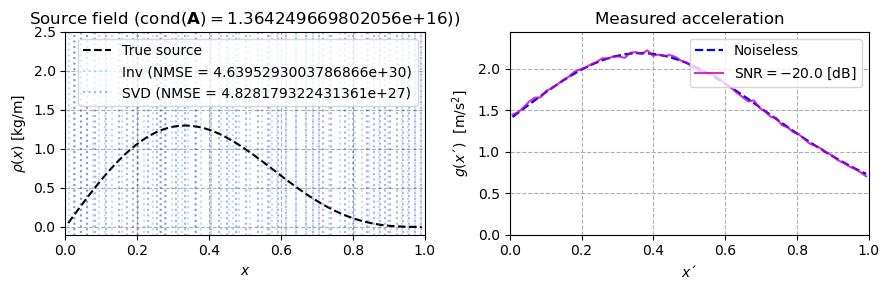

In [4]:
# Figure
fig, axs = plt.subplots(1, 2, figsize = (9,3))
axs[0].plot(x, rhox, '--k', label = "True source")
axs[0].plot(x, rhox_naive_inv, 'dodgerblue', linestyle = ':', label = "Inv (NMSE = {})".format(nmse_inv), alpha = 0.3)
axs[0].plot(x, rhox_naive_svd, 'navy', linestyle = ':', label = "SVD (NMSE = {})".format(nmse_svd), alpha = 0.3)
axs[0].legend()
axs[0].grid(linestyle = '--')
axs[0].set_xlim((0, 1))
axs[0].set_ylim((-0.1, 2.5))
axs[0].set_xlabel(r'$x$')
axs[0].set_ylabel(r'$\rho(x)$ [kg/m]')
axs[0].set_title(r'Source field (cond($\mathbf{{A}}) = ${}))'.format(cond_A))
axs[1].plot(x, gxl, label = r'Noiseless'.format(d), color = 'b', linestyle = '--', linewidth = 1.6)
axs[1].plot(x, gxln, label = r'SNR$ = {:.1f}$ [dB]'.format(snr), color = 'm', linestyle = '-', alpha = 0.8)
axs[1].grid(linestyle = '--')
axs[1].set_xlim((0, 1))
axs[1].set_ylim((0, 1.1*gxln.max()))
axs[1].legend(loc = 'upper right')
axs[1].grid(linestyle = '--')
axs[1].set_xlabel(r'$x´$')
axs[1].set_ylabel(r'$g(x´)$  [m/s$^2$]')
axs[1].set_title(r'Measured acceleration')
plt.tight_layout()

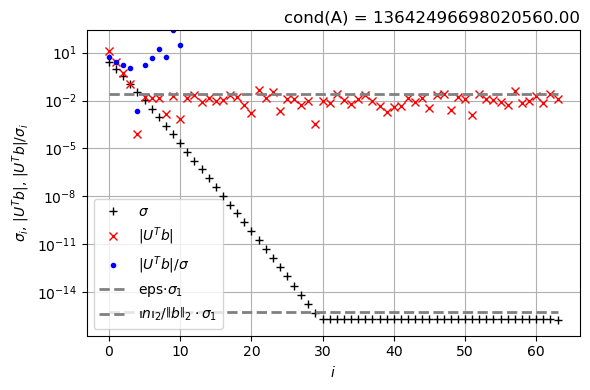

In [14]:
lc.plot_picard(U, s, gxln, noise_norm = np.linalg.norm(n), figsize = (6,4))

## 1. Métodos de regularização e caminho de regularização

No capítulo anterior investigamos alguns métodos que podemos usar para regularizar nossa solução, a saber

- Otimização com restrição (*constrained optimization*)
- SVD truncado (*Truncated SVD* - TSVD)
- Regularização de Tikhonov

### A. Otimização com restrição

Nos capítulos anteriores vimos uma forma de restringir a solução, dada por

\begin{equation}
\text{min}(\left\|\textbf{x}\right\|^{2}_{2}), \ \ \, \text{subjected to} \ \ \ \left\|\textbf{Ax -  b}\right\|^{2}_{2} \leq k \ \left\|\textbf{n}\right\|^{2}_{2}.
\tag{7}
\end{equation}

A ideia aqui é

- minimizar a norma da solução, $\mathbf{x}$,
- sujeito à condição de que a norma do resíduo, $\textbf{Ax -  b}$, seja menor ou igual ao produto de algum fator $k$ pela norma do ruído, $\textbf{n}$.

### B. SVD Truncado (*Truncated* SVD - TSVD)

A análise com o plot de Picard deixa evidente que os erros extremamente grandes na solução ingênua decorrem dos **componentes ruidosos da SVD**, associados aos menores valores singulares e às maiores frequências espaciais. A boa notícia é que nossa análise indica que uma parte dos valores singulares é confiável. Particularmente, os componentes para os quais $|\textbf{u}_{i}^{H}\textbf{b}| / \sigma_i \approx |\textbf{u}_{i}^{H}\textbf{b}_{\text{exa}}| / \sigma_i$ (claro, isso é válido se o valor exato da solução satisfizer o critério de Picard - o que é bastante razoável).

Estas considerações conduzem imediatamente a um método para calcular soluções aproximadas regularizadas: basta **eliminar** (ou zerar) os componentes do SVD dominados pelo ruído. Assim, definimos a solução SVD truncada (**TSVD** - *Truncated Singular Value Decomposition*), $\hat{\textbf{x}}_k$, como a solução obtida mantendo os primeiros $k$ componentes da solução ingénua, de modo que os fatores de filtragem da Eq.(6) sejam

\begin{equation}
    \varphi_{i}^{[k]} = 
    \begin{cases}
      1 \ \ \ \ \ \ \ 1 \leq i \leq k  \\
      0 \ \ \ \ \ \ \ k < i \leq L
    \end{cases}
\tag{8}
\end{equation}

### Ou seja,

- à medida que $k$ aumenta (número de componentes do SVD), o NMSE diminui em princípio. Passado um certo ponto, a inclusão de mais componentes de SVD torna-se prejudicial e o NMSE aumenta consideravelmente; 
- à medida que $k$ aumenta, a norma do resíduo ($r$) diminui. Para um $k$ muito alto teremos *overfitting* ou uma solução sub-regularizada;
- a norma da solução, $s$, aumenta à medida que $k$ cresce, tornando-se excessivamente grande para $k$ muito alto. O *overfitting* significa que o TSVD incluiu mais informação sobre o ruído do que sobre o termo fonte na solução;
- note também que $s$ tende a ser pequeno para $k$ muito pequeno. Isto corresponde a *underfitting* ou a uma solução sobre-regularizada. Neste caso, alguns dos componentes úteis (associados ao valor exato da solução) acabam sendo suprimidos. A consequência é uma solução que tende a ser sobre-suavizada.

### C. Regularização de Tikhonov

A vantagem do método **TSVD** é ser intuitivo e fácil de calcular as soluções, $\hat{\mathbf{x}}_k$, para diferentes valores de $k$. A desvantagem é que se trata de um método de força bruta, no qual os parâmetros de filtragem, $\varphi_i$, são truncados abruptamente. Na regularização de Tikhonov, tentamos equilibrar as normas do resíduo e da solução usando o seguinte problema de otimização

\begin{equation}
\hat{\textbf{x}}_{\lambda} = \text{min}(\left\|\textbf{Ax-b}\right\|^{2}_{2} + \lambda^2\left\|\textbf{x}\right\|^{2}_{2}).
\tag{9}
\end{equation}

Neste caso, os parâmetros de filtragem são

\begin{equation}
    \varphi_{i}^{[\lambda]} = \frac{\sigma_{i}^{2}}{\sigma_{i}^{2}+\lambda^2} \approx
    \begin{cases}
      1 \ \ \ \ \ \ \ \ \ \ \ \ \ \ \lambda \ll \sigma_i \\
      \sigma_{i}^{2}/\lambda^2 \ \ \ \ \ \ \ \lambda \gg \sigma_i
    \end{cases}
\tag{10}
\end{equation}

### Ou seja,

- à medida que $\lambda$ diminui, o NMSE diminui em princípio. Abaixo de certo ponto, o NMSE aumenta consideravelmente. 
- à medida que $\lambda$ diminui, a norma do resíduo ($r$) diminui. Para um $\lambda$ muito pequenos teremos *overfitting* ou uma solução sub-regularizada;
- a norma da solução, $s$, aumenta à medida que $\lambda$ diminui, tornando-se excessivamente grande para $\lambda$ muito pequeno. Neste caso, a solução de Tikhonov tende a solução por mínimos quadrados.
- note também que $s$ tende a ser pequeno para $\lambda$ muito grande. Isto corresponde a *underfitting* ou a uma solução sobre-regularizada. Neste caso, alguns dos componentes úteis (associados ao valor exato da solução) acabam sendo suprimidos. A consequência é uma solução que tende a ser sobre-suavizada.

### O caminho da regularização no TSDV e Tikhonov

Relembramos o caminho de regularização no TSVD e Tikhonov

In [15]:
ks = [2, 4, 6, 8, 10, 12, 14, 16 , 18]
rhox_k = []
nmse = []
sol_norm = []
res_norm = []
for k in ks:
    xk = lc.tsvd(U, s, V, gxln, k)
    rhox_k.append(xk)
    nmse.append(lc.nmse(xk, rhox))
    sol_norm.append(np.linalg.norm(xk))
    res_norm.append(np.linalg.norm(A@xk-gxln))

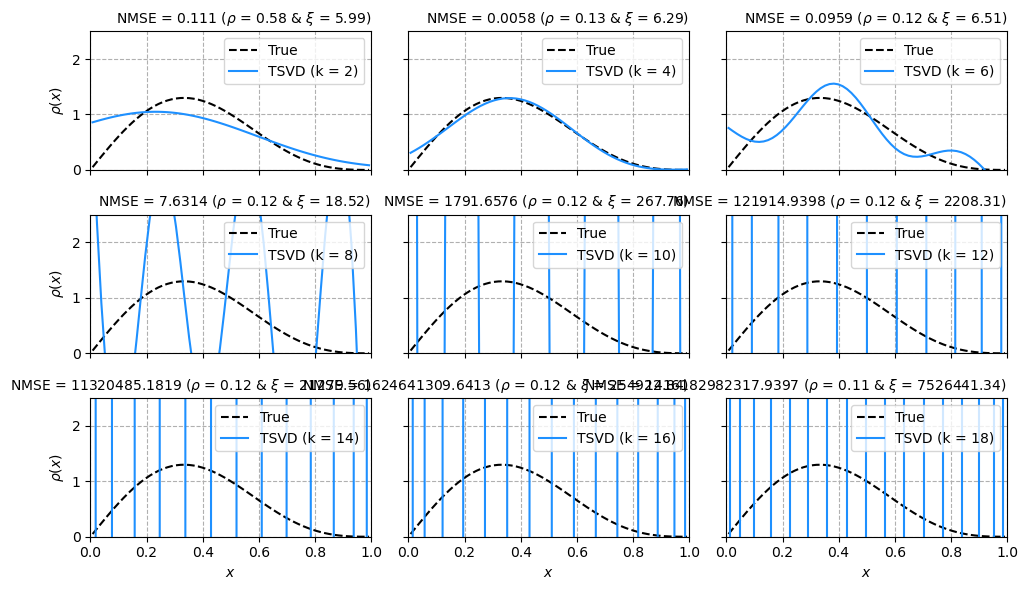

In [16]:
fig, axs = plt.subplots(3, 3, figsize = (10,6), sharex=True, sharey=True)
j = 0
for row in np.arange(3):
    for col in np.arange(3):
        axs[row,col].plot(x, rhox, '--k', label = 'True')
        axs[row,col].plot(x, rhox_k[j], color = 'dodgerblue', label = r'TSVD (k = {})'.format(ks[j]))
        axs[row,col].set_title(r'NMSE = {} ($\rho$ = {} & $\xi$ = {})'.format(np.round(nmse[j], 4), np.round(res_norm[j],2), 
                                                                         np.round(sol_norm[j],2)), loc = 'right', fontsize=10)
        axs[row,col].set_xlim((0, 1))
        axs[row,col].set_ylim((0, 2.5)); 
        axs[row,col].grid(linestyle = '--')
        axs[row,col].legend(loc = 'upper right')
        j += 1
        axs[2,col].set_xlabel(r'$x$')
    axs[row,0].set_ylabel(r'$\rho(x)$')
plt.tight_layout()

In [17]:
lambdas = [10, 2.5, 0.7, 0.2, 0.05, 0.015, 0.01, 0.0015 , 0.0005]
rhox_lam = []
nmse = []
sol_norm = []
res_norm = []
for lam in lambdas:
    xlam = lc.tikhonov(U, s, V, gxln, lam)
    sol_norm.append(np.linalg.norm(xlam))
    rhox_lam.append(xlam)
    nmse.append(lc.nmse(xlam, rhox))
    sol_norm.append(np.linalg.norm(xlam))
    res_norm.append(np.linalg.norm(A@xlam-gxln))

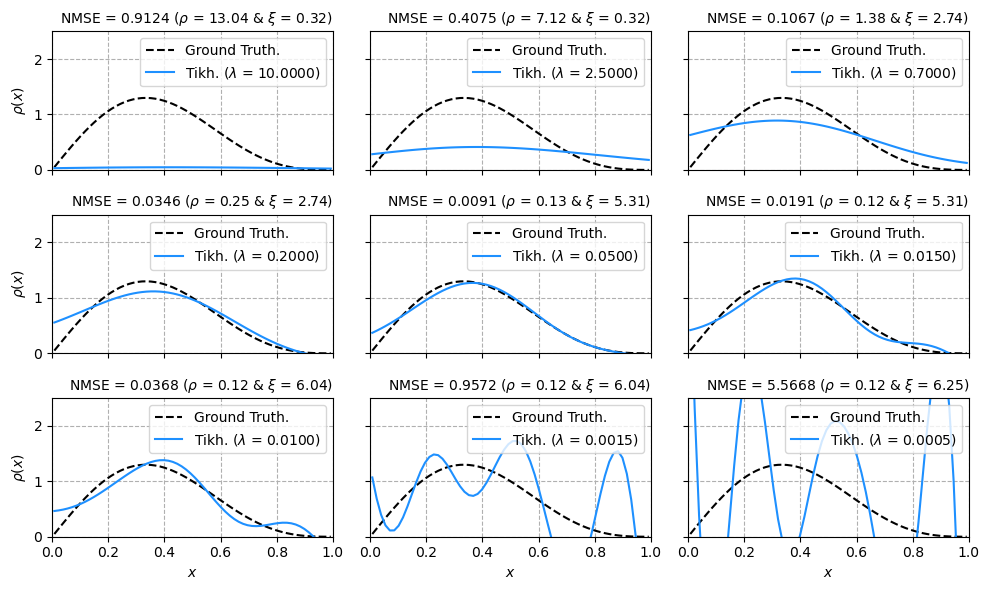

In [18]:
fig, axs = plt.subplots(3, 3, figsize = (10,6), sharex=True, sharey=True)
j = 0
for row in np.arange(3):
    for col in np.arange(3):
        axs[row,col].plot(x, rhox, '--k', label = 'Ground Truth.')
        axs[row,col].plot(x, rhox_lam[j], color = 'dodgerblue', label = r'Tikh. ($\lambda$ = {0:.4f})'.format(lambdas[j]))
        axs[row,col].set_title(r'NMSE = {} ($\rho$ = {} & $\xi$ = {})'.format(np.round(nmse[j], 4), np.round(res_norm[j],2), 
                                                                         np.round(sol_norm[j],2)), loc = 'right', fontsize=10)
        axs[row,col].set_xlim((0, 1))
        axs[row,col].set_ylim((0, 2.5)); 
        axs[row,col].grid(linestyle = '--')
        axs[row,col].legend(loc = 'upper right')
        j += 1
        axs[2,col].set_xlabel(r'$x$')
    axs[row,0].set_ylabel(r'$\rho(x)$')
plt.tight_layout()

# A curva L (L-curve)

Nossa análise dos três métodos de regularização revelou que:

- soluções **sub-regularizadas** ($\lambda$ pequeno - Tikhonov, $k$ grande - TSVD) tendem a possuir uma norma de solução, $\left\|\mathbf{x}\right\|_2$, muito grande e uma norma de resíduo,  $\left\|\mathbf{Ax-b}\right\|_2$ , pequena (*overfitting*);
- soluções **sobre-regularizadas** ($\lambda$ grande - Tikhonov, $k$ pequeno - TSVD) tendem a possuir uma norma de solução, $\left\|\mathbf{x}\right\|_2$, muito pequena e uma norma de resíduo,  $\left\|\mathbf{Ax-b}\right\|_2$ , grande (*underfitting*);

A questão que fica é: **Será que podemos buscar um ponto ótimo?**

O plot da curva L nos diz que sim:

In [19]:
# Several lambda values
lambdas = np.logspace(-5, 1, num=100) # logspace from 0.00001 to 10
# Solution and residual norms init
sol_norms = np.zeros(len(lambdas))
residuals = np.zeros(len(lambdas))
# loop
for jl, lam in enumerate(lambdas):
    xlam = lc.tikhonov(U, s, V, gxln, lam)
    sol_norms[jl] = np.linalg.norm(xlam)
    residuals[jl] = np.linalg.norm(A @ xlam - gxln)

chosen_indexes = [33, 41, 55, 75, 85, 95]

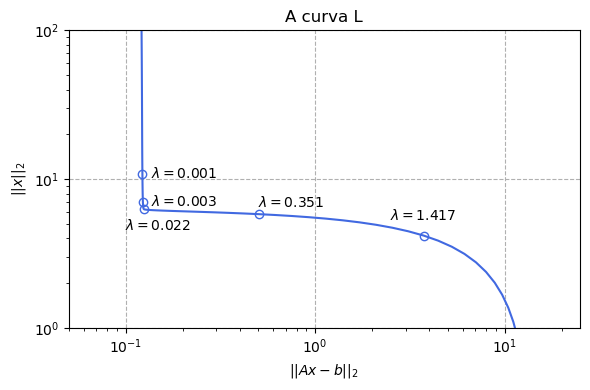

In [20]:
plt.figure(figsize = (6,4))
plt.loglog(residuals, sol_norms, color = 'Royalblue')
plt.loglog(residuals[chosen_indexes], sol_norms[chosen_indexes],  'o', color = 'Royalblue', markerfacecolor='none')
for num in chosen_indexes[:2]:
    label = r"$\lambda = ${:.3f}".format(lambdas[num])
    plt.annotate(label, (residuals[num], sol_norms[num]), textcoords="offset points", xytext=(30, -3), ha='center') 
for num in chosen_indexes[2:3]:
    label = r"$\lambda = ${:.3f}".format(lambdas[num])
    plt.annotate(label, (residuals[num], sol_norms[num]), textcoords="offset points", xytext=(10, -15), ha='center')
for num in chosen_indexes[3:4]:
    label = r"$\lambda = ${:.3f}".format(lambdas[num])
    plt.annotate(label, (residuals[num], sol_norms[num]), textcoords="offset points", xytext=(23, 5), ha='center')
for num in chosen_indexes[4:6]:
    label = r"$\lambda = ${:.3f}".format(lambdas[num])
    plt.annotate(label, (residuals[num], sol_norms[num]), textcoords="offset points", xytext=(0, 11), ha='center') 
plt.grid(linestyle = '--')
plt.ylim((1, 100))
plt.xlim((0.05, 25))
plt.xlabel(r'$||A x - b||_2$')
plt.ylabel(r'$||x||_2$')
plt.title("A curva L")
plt.tight_layout();

## Será que podemos usar algum algoritmo pra automatizar a busca pelo valor ótimo do parâmetro de regularização $k$ ou $\lambda$?


<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 1100px;">
A boa notícia é que sim e que existe mais de um método. No entanto, ao calcular a curva L acima, tivemos de obter diversas soluções do problema, $\hat{\textbf{x}}_{\lambda}$, variando $\lambda$. Isto vai consumir muitos recursos computacionais. Queremos fazer algo mais inteligente.
</div>

## 2. Escolha automática de $\lambda$ ou $k$

Desejamos uma técnica confiável e automatizada para escolher o parâmetro de regularização — $k$ (para TSVD) ou $\lambda$ (para Tikhonov). Especificamente, gostaríamos de ter um método eficiente, robusto e confiável para calcular o parâmetro de regularização a partir da matriz de sensibilidade ($\textbf{A}$) e dos dados medidos ($\textbf{b}$). 

Idealmente, não queremos depender de inspeção visual humana do plot de Picard, nem de múltiplas multiplicações matriciais ou de expansões em SVD (inviáveis para problemas de grande porte). Infelizmente, esse método ainda **não foi encontrado**. O que temos atualmente à nossa disposição é um conjunto de métodos que, sob certos pressupostos, tendem a **funcionar bem**. No entanto, todos eles podem e irão, ocasionalmente, falhar na obtenção de bons resultados. E, por ora, ao menos 1 cálculo de SVD também se mostra essencial em muitas situações.

Não é nossa intenção abranger todos os métodos desenvolvidos para a seleção automática do parâmetro de regularização. Em vez disso, concentramo-nos em quatro métodos diferentes, cada um com o seu próprio histórico e motivação, a saber

- O princípio da discrepância (*Discrepancy principle*);
- O critério da curva L (L-*curve creterion*);
- *Generalized Cross Validation* (GCV);
- *Normalized Cumulative Periodogram* (NCP);

Começamos com uma discussão sobre os erros na solução regularizada, que serve de motivação para os métodos de escolha de parâmetros e que conduz naturalmente aos dois primeiros métodos (*Discrepancy principle* & *L-curve*). Em seguida, descrevemos dois métodos baseados numa descrição estatística do problema (GCV & NCP). 

## 3. Erros de regularização e perturbação

Relembramos que a solução do problema de Tikhonov pode ser escrita na seguinte forma

\begin{equation}
\hat{\textbf{x}}_{\lambda} = \sum\limits_{i=1}^{L}\varphi_{i}\frac{\textbf{u}_{i}^{H}\textbf{b}}{\sigma_i} \textbf{v}_{i}.
\end{equation}

Em forma matricial

\begin{equation}
\hat{\textbf{x}} = \textbf{V}\Phi\Sigma^{-1}\textbf{U}^H \textbf{b}
\tag{11}
\end{equation}
com a matriz dos parâmetros de filtragem, dada por 

\begin{equation}
\Phi = \text{diag}(\varphi_1, \varphi_2, \cdots, \varphi_L)
\tag{12}
\end{equation}

Para a regularização de Tikhonov a matriz dos parâmetros de filtragem é

\begin{equation}
\Phi = \text{diag}(\frac{\sigma_{1}^{2}}{\sigma_{1}^{2} + \lambda^2}, \frac{\sigma_{2}^{2}}{\sigma_{2}^{2} + \lambda^2}, \cdots, \frac{\sigma_{L}^{2}}{\sigma_{L}^{2} + \lambda^2})
\end{equation}

Para TSVD essa matriz é

\begin{equation}
\Phi = \text{diag}(\underbrace{1, 1, 1, \cdots, 1}_{k \ \text{comp.}} , \underbrace{0, \cdots, 0}_{\text{restante}})
\end{equation}

Recordamos agora que em nosso sistema de equações

\begin{equation}
\mathbf{b} = \mathbf{A}\mathbf{x}_{\text{exa}} + \mathbf{n},
\end{equation}

o lado direito da igualdade consiste num "sinal" exato, $\mathbf{A}\mathbf{x}_{\text{exa}}$, somado ao ruído, $\mathbf{n}$. 

Podemos então analisar, teoricamente, a diferença entre a solução exata e a regularizada: $\mathbf{x}_{\text{exa}}-\hat{\mathbf{x}}$.


\begin{equation}
\begin{aligned}
\mathbf{x}_{\text{exa}} - \hat{\textbf{x}} &= \mathbf{x}_{\text{exa}} -  \textbf{V}\Phi\Sigma^{-1}\textbf{U}^H \textbf{b}\\
&= \mathbf{x}_{\text{exa}} -  \textbf{V}\Phi\Sigma^{-1}\textbf{U}^H (\textbf{A}\mathbf{x}_{\text{exa}}) - \textbf{V}\Phi\Sigma^{-1}\textbf{U}^H \textbf{n}\\
&= (\textbf{I}-\textbf{V}\Phi\underbrace{\Sigma^{-1}\textbf{U}^H \textbf{U} \Sigma}_{\mathbf{I}} \textbf{V}^{H})\mathbf{x}_{\text{exa}} - \textbf{V}\Phi\Sigma^{-1}\textbf{U}^H \textbf{n}\\
&= \underbrace{\textbf{V}(\textbf{I}-\Phi)\textbf{V}^H \ \mathbf{x}_{\text{exa}}}_{\text{bias}}-\underbrace{\textbf{V}\Phi\Sigma^{-1}\textbf{U}^H \textbf{n}}_{\text{ruído}}
\end{aligned}
\tag{13}
\end{equation}

A diferença entre a solução exata e a regularizada possui, portanto, dois termos: 
- **bias** (viés da solução ou erro sistemático) e
- **ruído** (de natureza aleatória).

### A. Bias (viés ou erro sistemático)

O primeiro termo (**bias**) é dado por

\begin{equation}
\Delta x_{\text{bias}} = \textbf{V}(\textbf{I}-\Phi^{[\lambda]})\textbf{V}^H \ \mathbf{x}_{\text{exa}} = \sum\limits_{i=1}^{L}(1-\varphi_{i})(\textbf{v}^{H}_{i}\mathbf{x}_{\text{exa}})\textbf{v}_{i}
\tag{14}
\end{equation}

### Como o viés varia com o parâmetro de regularização? 
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
- Se você escolhe uma solução mais regularizada (aumentando $\lambda$ ou diminuindo $k$) o viés **aumenta**,  já que $\varphi_i$ diminui e $1-\varphi_i$ aumenta. Isto corresponde a uma solução sobre-suavizada, com menor norma.
</details> 

### B. Ruído (ou erro de perturbação)

O segundo termo se deve ao **ruído**, e é dado por

\begin{equation}
\Delta x_{\text{pert}} = \textbf{V}\Phi\Sigma^{-1}\textbf{U}^H \textbf{n} = \sum\limits_{i=1}^{L}\varphi_{i}\frac{\textbf{u}^{H}_{i}\textbf{n}}{\sigma_i}\textbf{v}_{i}
\tag{15}
\end{equation}

### Como o erro de perturbação varia em função do parâmetro de regularização?
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
- Se você escolhe uma solução mais regularizada (aumentando $\lambda$ ou diminuindo $k$) o erro de perturbação **diminui**,  já que se está filtrando as componentes de mais alta frequência no sinal, diminuindo $\varphi_i$.
- Se você vai na direção contrária, o erro de perturbação aumenta (mais componentes de ruído na solução), mas o viés tende a diminuir (no extremo, tendemos ao *over-fitting*);
</details> 

Os erros de **bias** e **perturbação** estão sempre presentes na solução regularizada, e a sua dimensão depende do parâmetro de regularização. Para TSVD, Se $k$ for próximo de $\text{min}(M,L)$, então a maioria dos componentes da SVD são incluídos e o **bias** é pequeno, mas o erro de **perturbação** é grande porque aplicamos pouca filtragem. Por outro lado, se $k$ for pequeno, então muitos componentes da SVD são deixados de fora e, assim, o erro de **perturbação** será pequeno, mas o erro de **bias** será grande. O mesmo é verdade para a escolha do parâmetro de regularização de Tikhonov. Se $\lambda$ for muito pequeno, então todos os fatores de filtro $\varphi_{i}$ estão próximos de $1$. Portanto, $\Phi \approx \textbf{I}$, e o erro de **bias** é pequeno (enquanto o erro de **perturbação** é grande). E se $\lambda$ for grande, então muitos fatores de filtragem são pequenos, e assim o erro associado à **perturbação** será também pequeno, mas então $\Phi$ não está perto da matriz identidade, e o erro de **bias** será grande.

Por conseguinte, podemos dizer que o objetivo ao escolher $k$ ou $\lambda$ é **equilibrar** a dimensão dos dois termos de erro $\Delta x_{\text{bias}}$ e $\Delta x_{\text{pert}}$.

## 4. As normas do resíduo e solução

Nós já estabelecemos um fato importante: as normas do **resíduo** e da **solução** desempenham um papel central na determinação de um parâmetro ótimo de regularização — o que está ligado à intuição construída na análise da curva L. Além disso, tais normas podem ser computadas independentemente da escolha do método de regularização. Nós vamos usar o SVD por ora, mas as normas em si não precisam necessariamente disso. Seguindo o princípio do equilíbrio entre **bias** e **perturbação** e a intuição dada na análise da curva L, vamos usar os símbolos $\rho$ e $\xi$ para designar os quadrados das normas do **resíduo** e da **solução**, respectivamente. 

Para o método TSVD, $\rho$ e $\xi$ são dados por

\begin{equation}
\begin{gathered}
\xi = \left\|\textbf{x}_{k}\right\|_{2}^{2}=\sum_{i=1}^{k}\left(\frac{\textbf{u}_{i}^{H} \textbf{b}}{\sigma_{i}}\right)^{2} \\
\rho = \left\|\textbf{A x}_{k}-\textbf{b}\right\|_{2}^{2}=\sum_{i=k+1}^{L}\left(\textbf{u}_{i}^{H} \textbf{b}\right)^{2} + \epsilon^2_\bot
\end{gathered},
\tag{15}
\end{equation}
em que $\epsilon_\bot = \left\|\mathbf{I}-\mathbf{U}\mathbf{U}^H \mathbf{b}\right\|$ é a norma dos componentes de $\mathbf{b}$ fora do espaço de colunas de $\mathbf{A}$. Note que $\xi = \left\|\textbf{x}_{k}\right\|_{2}^{2} \leq \left\|\textbf{x}_{k+1}\right\|_{2}^{2}$ e que $\rho = \left\|\textbf{A x}_{k}-\textbf{b}\right\|_{2}^{2} \geq \left\|\textbf{A x}_{k+1}-\textbf{b}\right\|_{2}^{2}$.

De forma similar, as normas $\rho$ e $\xi$ para a regularização de Tikhonov são

\begin{equation}
\begin{gathered}
\xi = \left\|\textbf{x}_{\lambda}\right\|_{2}^{2}=\sum_{i=1}^{L}\left(\varphi_{i}^{[\lambda]} \frac{\textbf{u}_{i}^{H} \textbf{b}}{\sigma_{i}}\right)^{2}, \\
\rho = \left\|\textbf{A x}_{\lambda}-\textbf{b}\right\|_{2}^{2}=\sum_{i=1}^{L}\left(\left(1-\varphi_{i}^{[\lambda]}\right) \textbf{u}_{i}^{H} \textbf{b}\right)^{2}+ \epsilon^2_\bot
\end{gathered},
\tag{16}
\end{equation}

mas note que os parâmetros de filtragem $\varphi_{i}$ estão embutidos na Eq. (16). Isto não ocorre na Eq. (15) devido à natureza do filtro.

Nosso algoritmo genérico para encontrar os valores ideais de $\lambda$ ou $k$ vai realizar um processo de busca de mínimo ou máximo de uma função $R(\lambda)$ ou $R(k)$. Tal função vai se utilizar das normas $\rho$ e $\xi$. Assim, é importante conhecer as derivadas de primeira e segunda ordem de $\rho$ e $\xi$ em função de $\lambda$ ou de $k$ (neste último caso trivial). No caso da regularização de Tikhonov, temos que

\begin{equation}
\begin{gathered}
\xi^{\prime} \equiv \frac{d \xi}{d \lambda}=-\frac{4}{\lambda} \sum_{i=1}^{n}\left(1-\varphi_{i}^{[\lambda]}\right)\left(\varphi_{i}^{[\lambda]}\right)^{2} \frac{\left(\textbf{u}_{i}^{H} \textbf{b}\right)^{2}}{\sigma_{i}^{2}}, \\
\rho^{\prime} \equiv \frac{d \rho}{d \lambda}=\frac{4}{\lambda} \sum_{i=1}^{n}\left(1-\varphi_{i}^{[\lambda]}\right)^{2} \varphi_{i}^{[\lambda]}\left(\textbf{u}_{i}^{H} \textbf{b}\right)^{2}=-\lambda^{2} \xi^{\prime} .
\end{gathered}
\tag{17}
\end{equation}



Vemos que $\xi^{\prime}<0$ e $\rho^{\prime}>0$ para todo $\lambda$, o que confirma a monotonicidade das normas como funções de $\lambda$. Além disso, a partir da relação $\rho^{\prime}=-\lambda^{2} \xi^{\prime}$, obtemos $d \xi / d \rho=-\lambda^{-2}$, o que mostra que o quadrado da norma da solução, $\left\|\textbf{x}_{\lambda}\right\|_{2}^{2}$, é uma função decrescente  monotonicamente do quadrado da norma residual. Uma vez que a função raiz quadrada também é monotónica, o mesmo é verdade para as próprias normas.

Existe também uma relação simples entre as segundas derivadas de $\xi$ e de $\rho$. Especificamente, temos

\begin{equation}
\rho^{\prime \prime} \equiv \frac{d^{2} \rho}{d \lambda^{2}}=\frac{d}{d \lambda}\left(-\lambda^{2} \xi^{\prime}\right)=-2 \lambda \xi^{\prime}-\lambda^{2} \xi^{\prime \prime},
\tag{18}
\end{equation}

## 5. A lógica geral dos métodos de seleção automática

Nós desejamos computar uma função $R(\lambda)$ [ou $R(k)$]. Seu ponto mínimo (ou máximo) indicará o ponto, $\lambda$ ou $k$, da função que será uma boa **estimativa** para o parâmetro de regularização ótimo. Veja, por exemplo, as curvas típicas dos métodos L-curve e GCV

<figure style="text-align: center;">
    <img src="\..\figs\Lcurve.png" width="400" alt="Imagem da Lcurve típica.">
    <img src="\..\figs\GCVcurve.png" width="400" alt="Imagem da GCV curve típica.">
    <figcaption style="margin-top: 8px; font-style: italic; color: #555;">
        Figura 2: Funções típicas para a busca do parâmetro ótimo de regularização: (a) L-curve; (b) GCV.
    </figcaption>
</figure>

Usaremos os dados ruidosos em $\textbf{b}$ e a expansão SVD de $\textbf{A}$. Os passos gerais de uma algoritmo são:

$$
\begin{array}{l}
\textbf{Algoritimo: Escolha do parâmetro de regularização} \\
\hline
\textbf{Input:} \ \text{SVD de \textbf{A}} \ (\textbf{U}, \Sigma, \textbf{V}), \ \text{medição} \ (\textbf{b}), \ \text{função: } R(\lambda), \ tol = 16*eps  \\
\textbf{Computar: } \beta = \textbf{U}^{H} \textbf{b} \\
\textbf{Computar: } r = \left\|\textbf{b}\right\|^{2}_{2} -  \left\|\textbf{U}^{H} \textbf{b}\right\|^{2}_{2} \ \text{(componentes de $\mathbf{b}$ fora do espaço de colunas de $\mathbf{A}$)} \\
\textbf{Inicializar: } \lambda \ \& \ R(\lambda) \ \text{com zeros (e.g. $npts = 200$ zeros)} \\
\textbf{Preencher último valor de $\lambda$: } \lambda[-1] = \text{max}(s[-1], s[0] \cdot tol)\\
\textbf{Computar: } \ \text{uma razão numérica: }  \text{ratio} = \left(\frac{\sigma[0]}{\lambda[-1]}\right)^{1/(npts-1)}\\
\textcolor{grey}{\textbf{\# Loop: }\text{Preenchimento de $\lambda$ do fim ao início. Isto faz com que a escala em $\lambda$ seja preenchida razoavelmente,}}\\ 
\hspace{2cm} \textcolor{grey}{\text{de acordo com a razão entre os maiores e os menores valores singulares do problema.}}\\
\textbf{for } i = -2 \text{ to } -L \textbf{:} \ \\
\ \ \ \ \lambda[i] = \text{ratio} \cdot \lambda[i+1]\\
\textbf{end for} \\
\textbf{Computar: } \ \text{de posse dos valores discretos em $\lambda$, computamos a versão discreta $R(\lambda)$, usando $\textbf{U}$, $\Sigma$, $\textbf{V}, \textbf{b}$}\\
\textbf{Computar: } \ \text{o valor mínimo dessa função discreta $R(\lambda)$ e o correspondente $\lambda^{\prime}$}\\
\textbf{Encontrar: } \ \text{um valor à esquerda de $\lambda^{\prime}$ e outro à direita: $(\lambda_{\text{min}}, \lambda_{\text{max}})$;}\\
\hspace{2.8cm}\text{tais valores servirão como uma restrição num espaço de busca contínuo.}\\
\textbf{Otimizar: } \ \text{usamos um algoritmo de otimização para encontrar o valor ideal de $\lambda$ entre $(\lambda_{\text{min}}, \lambda_{\text{max}})$}\\
\textbf{Return } \lambda \\
\hline
\end{array}
$$

```python
def get_regpar(s_valid, npoints = 200, r_min = 16 * np.finfo(float).eps):
    """
    Generate an initial search grid for the regularization parameter.

    Constructs a logarithmically spaced grid of candidate Tikhonov
    regularization parameters :math:`\\lambda`. The grid spans from the
    largest singular value to a lower bound determined by the larger of
    the smallest retained singular value and a prescribed fraction of
    the largest singular value.

    Parameters
    ----------
    s_valid : ndarray, shape (p,)
        Valid range of singular values, ordered from largest to smallest.
        Typically, ``p`` corresponds to the number of singular values
        retained for the parameter-choice procedure.
    npoints : int, default=200
        Number of regularization parameters in the search grid.
    r_min : float, default=16 * eps
        Minimum regularization parameter relative to the largest singular
        value. Here, ``eps`` denotes machine precision for a floating-point
        number. The lower end of the search grid cannot be smaller than
        ``s_valid[0] * r_min``.

    Returns
    -------
    reg_par_grid : ndarray, shape (npoints,)
        Logarithmically spaced regularization-parameter grid, ordered from
        largest to smallest.
    """
    last_val = max(s_valid[-1], s_valid[0] * r_min)
    reg_par_grid = np.geomspace(s_valid[0], last_val, npoints)
    return reg_par_grid
```

## 6. Métodos de escolha automática

### A. Discrepancy principle (DP)

Vamos começar pelo mais **simples** e intuitivo. Talvez isso seja mais um resgate do que uma apresentação completa de algo novo. O princípio da **discrepância** nos diz que devemos escolher o parâmetro $k$ (TSVD) ou $\lambda$ (Tikhonov) de modo a que a norma residual ($\rho$) seja maior ou igual à norma do ruído ($\left\|\textbf{n}\right\|_{2}$), multiplicada por um fator real $\upsilon_{\text{DP}}$. Então o produto $\upsilon_{\text{DP}}\left\|\textbf{n}\right\|_{2}$ é chamado de **discrepância**.

No caso de TSVD, escolhemos

<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 1100px;">
\begin{equation}
\text{Escolha} \ \ \ k  \ \ \ \text{Tal que} \ \ \ \rho = \left\|\textbf{A}\textbf{x}_k-\textbf{b}\right\|_{2}\geq\upsilon_{\text{DP}}\left\|\textbf{n}\right\|_{2}
\tag{19}
\end{equation}
</div>


A mesma estratégia pode ser usada para o método de Tikhonov, a saber

<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 1100px;">
\begin{equation}
\text{Escolha} \ \ \ \lambda  \ \ \ \text{Tal que} \ \ \ \rho = \left\|\textbf{A}\textbf{x}_{\lambda}-\textbf{b}\right\|_{2} = \upsilon_{\text{DP}}\left\|\textbf{n}\right\|_{2}
\tag{20}
\end{equation}
</div>


Em ambos os casos, há uma solução única, já que $\rho$ varia monotonicamente com $k$ e $\lambda$.

A principal vantagem computacional do DP é sua simplicidade. Apenas a norma do resíduo está envolvida e tudo de que precisamos é de um algoritmo de busca de raiz.

```python
def discrep(u, s, b, noise_norm):
    """
    Select the Tikhonov regularization parameter using the discrepancy
    principle.

    Parameters
    ----------
    u : ndarray
        Matrix containing the left singular vectors of the forward matrix.
    s : ndarray, shape (p,)
        Singular values, ordered from largest to smallest.
    b : ndarray, shape (M,)
        Measurement vector.
    noise_norm : float
        Estimated norm of the measurement noise,
        :math:`\\|\\mathbf{n}\\|_2`.

    Returns
    -------
    reg_min : float
        Tikhonov regularization parameter selected by the discrepancy
        principle.
    """
    beta = u.conj().T @ b
    beta_perp_sq = max(np.linalg.norm(b)**2 - np.linalg.norm(beta)**2, 0.0)
    if noise_norm**2 < beta_perp_sq:
        raise ValueError(
            "Noise norm is smaller than the minimum achievable residual norm."
        )
    
    lambda_min, lambda_max = 0, s[0]
    # Increase upper bound until the root is bracketed
    while discrepancy_fun(lambda_max, s, beta, beta_perp_sq, noise_norm) < 0:
        lambda_max *= 2.0
    reg_min = optimize.brentq(discrepancy_fun, lambda_min, lambda_max,
        args=(s, beta, beta_perp_sq, noise_norm))
    return reg_min
```

```python
def discrepancy_fun(lambda_val, s, beta, beta_perp_sq, noise_norm):
    """
    Evaluate the discrepancy-principle function.

    Computes the difference between the squared norm of the Tikhonov
    residual and the squared norm of the measurement noise,

    Parameters
    ----------
    lambda_val : float
        Tikhonov regularization parameter.
    s : ndarray, shape (p,)
        Singular values.
    beta : ndarray, shape (p,)
        Expansion coefficients of the measurement vector in the left
        singular-vector basis.
    beta_perp_sq : float
        Squared norm of the component of the measurement vector orthogonal
        to the subspace spanned by the left singular vectors.
    noise_norm : float
        Norm of the measurement noise, :math:`\\|\\mathbf{n}\\|_2`.

    Returns
    -------
    discrepancy : float
        Difference between the squared residual norm and the squared
        measurement-noise norm.
    """

    cf = complement_filter_factors(lambda_val, s)
    residual_sq = (np.linalg.norm(cf * beta)**2 + beta_perp_sq)
    return residual_sq - noise_norm**2
```

A principal desvantagem do DP é que, muitas vezes, não conhecemos a norma do ruído, $\left\|\textbf{n}\right\|_2$, com exatidão. Infelizmente, a qualidade do parâmetro de regularização obtido é muito sensível à precisão da estimativa de $\upsilon_{\text{DP}}\left\|\textbf{n}\right\|_{2}$. Em particular, uma estimativa demasiado pequena pode levar a um dramático *over-fitting* ($k$ é escolhido demasiado grande e $\lambda$ é demasiado pequeno). O contrário também ocorre quando ou  $\upsilon_{\text{DP}}$ ou $\left\|\textbf{n}\right\|_2$ são sobreestimados.

Vejamos o que acontece para vários valores de $\upsilon_{\text{DP}}$. Na prática, isso equivale a subestimar ou sobreestimar $\left\|\textbf{n}\right\|_2$.

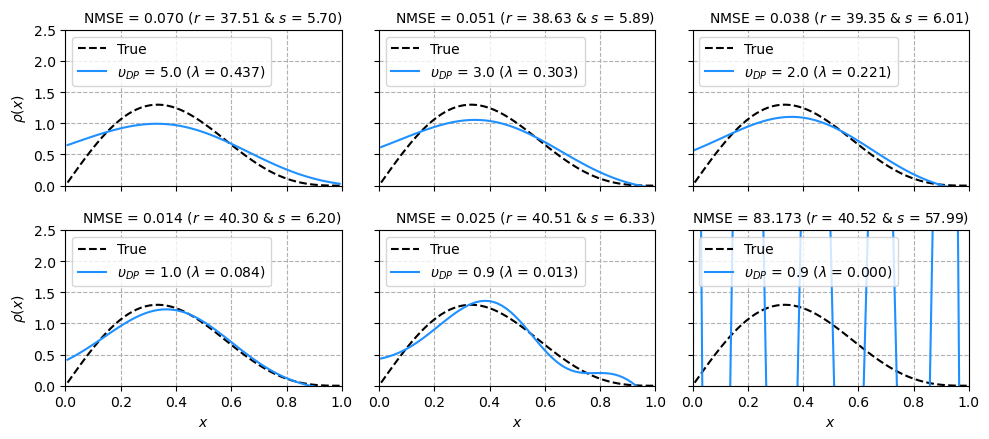

In [5]:
vdps = [5, 3, 2, 1, 0.9, 0.88]
rhox_dp = []
lam_dps = []
nmse = []
sol_norm = []
res_norm = []
for j, vdp in enumerate(vdps):
    x_dp, lam_dp = lc.discrep(U, s, V, gxln, vdp*np.linalg.norm(n))
    rhox_dp.append(x_dp.flatten())
    lam_dps.append(lam_dp[0])
    nmse.append(lc.nmse(x_dp.flatten(), rhox))
    sol_norm.append(np.linalg.norm(x_dp))
    res_norm.append(np.linalg.norm(A @ x_dp - gxln))
    
fig, axs = plt.subplots(2, 3, figsize = (10,4.5), sharex=True, sharey=True)
j = 0
for row in np.arange(2):
    for col in np.arange(3):
        axs[row,col].plot(x, rhox, '--k', label = 'True')
        axs[row,col].plot(x, rhox_dp[j], color = 'dodgerblue', linewidth = 1.5, 
                          label = r'$\upsilon_{{DP}}$ = {:.1f} ($\lambda$ = {:.3f})'.format(vdps[j], lam_dps[j]))
        axs[row,col].set_title(r'NMSE = {:.3f} ($r$ = {:.2f} & $s$ = {:.2f})'.format(np.round(nmse[j], 4), np.round(res_norm[j],2), 
                                                                         np.round(sol_norm[j],2)), loc = 'right', fontsize=10)
        #axs[row,col].set_title(r'NMSE = {0:.6f}'.format(nmse[j]))
        axs[row,col].set_ylim((0.5*np.amin(rhox),1.1*np.amax(rhox)));  
        axs[row,col].grid(linestyle = '--')
        axs[row,col].legend(loc = 'upper left')
        axs[row,col].set_xlim((0, 1))
        axs[row,col].set_ylim((0, 2.5)) 
        j += 1
        axs[1,col].set_xlabel(r'$x$')
    axs[row,0].set_ylabel(r'$\rho(x)$')
plt.tight_layout()
#print(r'$\lambda = $ {}'.format(lam_dps))

### B. Máxima curvatura da curva L (L-curve crieterion)

Vimos que a curva L desempenha um papel interessante na regularização de problemas inversos. O caminho de regularização implica que, para $\lambda$ muito pequeno (ou $k$ muito grande), temos uma norma de solução, $\left\|\mathbf{x}\right\|_2$, elevada e uma norma de resíduo, $\left\|\mathbf{Ax}-\mathbf{b}\right\|_2$, pequena (tendência a *overfitting*). À medida que $\lambda$ aumenta (ou $k$ diminui), $\left\|\mathbf{x}\right\|_2$ diminui, enquanto  $\left\|\mathbf{Ax}-\mathbf{b}\right\|_2$ aumenta. Passado o ponto ótimo, teremos um problema sobre-regularizado, com muitas das componentes úteis filtradas da solução. 

<figure style="text-align: center;">
    <img src="\..\figs\Lcurve.png" width="400" alt="Imagem da Lcurve típica.">
    <figcaption style="margin-top: 8px; font-style: italic; color: #555;">
        Figura 3: Curva L típica.
    </figcaption>
</figure>


O critério da curva L baseia-se em encontrar o valor máximo da função $R(\lambda)$, dada pela **curvatura** da própria curva L. Como tal curva é expressa numa escala log-log, podemos introduzir a notação

\begin{equation}
\begin{gathered}
\hat{\xi}=\log \left\|\textbf{x}\right\|_{2}^{2} \quad \text{ou} \quad \hat{\xi}=\log(\xi) \\
\hat{\rho}=\log \left\|\textbf{A x}-\textbf{b}\right\|_{2}^{2} \quad \text{ou} \quad \hat{\rho}=\log(\rho)
\end{gathered}
\tag{21}
\end{equation}

As derivadas de ordem 1 são

\begin{equation}
\begin{gathered}
\hat{\xi}^{\prime}=\frac{\xi^{\prime}}{\xi} \\
\hat{\rho}^{\prime}=\frac{\rho^{\prime}}{\rho}
\end{gathered}
\tag{22}
\end{equation}

As derivadas de ordem 2 são

\begin{equation}
\begin{gathered}
\hat{\xi}^{\prime \prime}=\frac{\xi^{\prime \prime} \xi-\left(\xi^{\prime}\right)^{2}}{\xi^{2}} \\
\hat{\rho}^{\prime \prime}=\frac{\rho^{\prime \prime} \rho-\left(\rho^{\prime}\right)^{2}}{\rho^{2}}
\end{gathered}
\tag{23}
\end{equation}


### Curvatura

A **curvatura** da curva L, $C(\lambda)$, é dada por

\begin{equation}
C(\lambda)=\frac{\hat{\rho}^{\prime} \hat{\xi}^{\prime \prime}-\hat{\rho}^{\prime \prime} \hat{\xi}^{\prime}}{\left[\left(\hat{\rho}^{\prime}\right)^{2}+\left(\hat{\xi}^{\prime}\right)^{2}\right]^{3 / 2}}=\frac{2 \lambda\left(\hat{\xi}^{\prime}\right)^{2}}{\left[\left(\hat{\rho}^{\prime}\right)^{2}+\left(\hat{\xi}^{\prime}\right)^{2}\right]^{3 / 2}},
\tag{24}
\end{equation}

ou

\begin{equation}
C(\lambda)=2 \frac{\xi \rho}{\xi^{\prime}} \frac{\lambda^{2} \xi^{\prime} \rho+2 \lambda \xi \rho+\lambda^{4} \xi \xi^{\prime}}{\left(\lambda^{2} \xi^{2}+\rho^{2}\right)^{3 / 2}}.
\tag{25}
\end{equation}


Podemos então, fazer o seguinte:

<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 1100px;">
\begin{equation}
\text{Escolha} \ \ \ \lambda  \ \ \ \text{para maximizar} \ \ \ C(\lambda)
\tag{26}
\end{equation}
</div>

#### Vejamos algum código (as partes mais importantes)

Note as partes gerais do algoritmo dado anteriormente.

```python
def l_curve_new(u, s, b, smin_ratio = 16 * np.finfo(float).eps, 
            plotit = False, plot_in_color = True):
    """ Optimal regularization parameter via the L-curve criterion.

    This function uses the L-curve and computes its curvature in
    order to find its corner - optimal regularization parameter.

    Uses the function "l_corner"

    Parameters
    ----------
        U : numpyndArray
            Left singular vectors matrix
        s : numpy1dArray
            Singular values
        b : numpy1dArray
            Measurement vector
        smin_ratio : float
            ratio to first singular value. Odds are that the minimum regularization 
            parameter will be s[0]*smin_ratio
        plotit : bool
            whether to plot the L curve or not. Default is False
        plot_in_color : bool
            choose to plot the regularization function in color or black and white.
        
    Returns
    -------
        lam_opt : float
            optimal regularization parameter
    """
    # Sizes and shapes
    npoints = 200  # Number of points on the L-curve    
    p = len(s)
    # Initial search grid
    reg_param = get_regpar(s_valid = s[:p], npoints = npoints, smin_ratio = smin_ratio)
    # Compute everything
    lam_opt, curv, rho_c, eta_c, eta, rho = l_corner_new(reg_param,u,s,b)
```

```python
def l_corner_new(reg_param,u,s,b):
    """ Computes the corner of the L-curve.

    Uses the function "curvature1d" (see Sec. 5.4 of Discrete Inverse Problems)

    Parameters
    ----------
        rho : numpy 1darray
            computed in l_curve function (residual norm) - related to curvature
        eta : numpy 1darray
            computed in l_curve function (solution norm) - related to curvature
        reg_param : numpy 1darray
            computed in l_curve function
        u : numpy ndarray
            left singular vectors
        sig : numpy 1darray
            singular values
        bm: numpy 1darray
            your measurement vector (size: Nm x 1)
    Returns
    -------
        reg_c : float
            optimal regularization parameter
    """
    p = len(s)
    beta = np.conj(u.T) @ b # data projection 
    b0 = b - u @ beta # residual numerical correction
    beta2 = np.linalg.norm(b) ** 2 - np.linalg.norm(beta)**2
    # U^H @ b/sig
    xi = beta[:p]/s  
    xi[np.isinf(xi)] = 0
    # Filter factors, residual and solution norms
    Nm, Nu = u.shape
    eta, rho = f_eta_rho(reg_param, s, xi, beta, beta2, Nm, Nu)  
    order = 4  # Order of fitting 2-D spline curve.
    # Initialization.
    if (len(rho) < order):
        print('I will fail. Too few data points for L-curve analysis')
    # Call curvature calculator
    curv = np.zeros(len(reg_param))
    for i in np.arange(len(reg_param)):
        curv[i] = curvature_new(reg_param[i], s, beta, xi) # ok    
    # Initial minimization    
    x1, x2, tolerance = get_bounds(vec_to_minimize = curv, reg_par_vec = reg_param)
    # Refined minimization
    reg_c = optimize.fminbound(curvature_new, x1, x2, args = (s, beta, xi), xtol=tolerance,
        full_output=False, disp=False)
    # Final evaluation
    kappa_max = -curvature_new(reg_c, s, beta, xi) # Maximum curvature.
    if kappa_max < 0:
        lr = len(rho)
        reg_c = reg_param[lr-1]
        rho_c = rho[lr-1]
        eta_c = eta[lr-1]
    else:
        f = np.divide((s**2), (s**2 + reg_c**2))
        eta_c = np.linalg.norm(f * xi)
        rho_c = np.linalg.norm((1-f) * beta[0:len(f)])
        if Nm > Nu:
            rho_c = np.sqrt(rho_c ** 2 + np.linalg.norm(b0)**2)
    return reg_c, curv, rho_c, eta_c, eta, rho
```

### Algumas palavras de cautela:

- O critério da curva L é essencialmente heurístico, e não há garantia de que produzirá sempre um bom parâmetro de regularização. Um exemplo em que é suscetível a falhar ocorre quando $\textbf{x}_{\text{exa}}$ é muito suave (dominado pelos primeiros vetores singulares à direita). A quina da curva L está localizada no ponto em que a norma da solução passa a ser dominada pelos componentes ruidosos da SVD. Parece um contrassenso, mas, nestes casos, o parâmetro de regularização tende a ser subestimado, o que leva a uma solução menos suave do que a solução exata.

- Outro exemplo em que o critério da curva $L$ pode falhar ocorre quando as alterações de $rho$ e $\xi$ são pequenas. Neste caso, é difícil determinar com precisão a quina da curva $L$. Infelizmente este comportamento dos coeficientes é frequentemente observado em problemas de grande escala.

- Uma última observação crítica sobre o comportamento do critério da curva $L$: se $\left\|n\right\|_{2}\rightarrow 0$, então o parâmetro de regularização, $\lambda$ tende a divergir do ótimo. Este comportamento indesejável de não-convergência não é partilhado pelo princípio da discrepância (ou GCV, discutido a seguir). Felizmente, $\left\|n\right\|_{2}\rightarrow 0$ é uma situação rara.

### Vejamos o critério da curva L no problema investigado

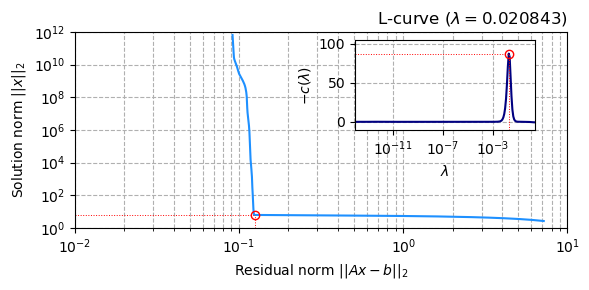

In [8]:
lam_lc = lc.l_curve_new(U, s, gxln, plotit = True, plot_in_color = True)

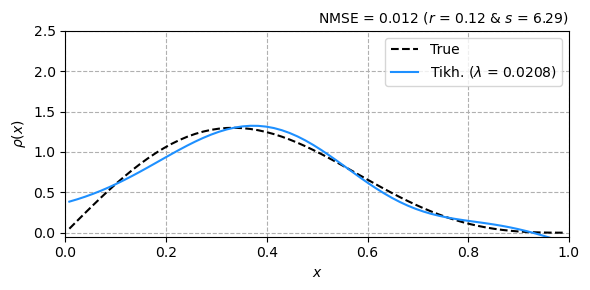

In [16]:
x_lc = lc.tikhonov(U, s, V, gxln, lam_lc)
nmse_lc = lc.nmse(x_lc, rhox)  
res_norm = np.linalg.norm(A @ x_lc - gxln)
sol_norm = np.linalg.norm(x_lc)

plt.figure(figsize = (6,3))
plt.plot(x, rhox, '--k', label = 'True')
plt.plot(x, x_lc, color = 'dodgerblue', linewidth = 1.5, label = r'Tikh. ($\lambda$ = {0:.4f})'.format(lam_lc))
plt.title(r'NMSE = {:.3f} ($r$ = {:.2f} & $s$ = {:.2f})'.format(np.round(nmse_lc, 4), np.round(res_norm,2),
                                                                np.round(sol_norm,2)), loc = 'right', fontsize=10)
plt.ylim((0.5*np.amin(rhox),1.1*np.amax(rhox)));  
plt.grid(linestyle = '--')
plt.legend()
plt.xlim((0, 1))
plt.ylim((-0.05, 2.5)) 
plt.xlabel(r'$x$')
plt.ylabel(r'$\rho(x)$')
plt.tight_layout()

## C. Generalized cross-validation (GCV)

A ideia fundamental por trás deste método é usar uma técnica de validação de dados para encontrar o valor de $\lambda$ (ou $k$), de forma que $\mathbf{Ax}_{\lambda}$ (ou $\mathbf{Ax}_{k}$) seja a melhor aproximação possível para $\textbf{b}_{\text{exa}}$ (o qual não possuímos).



Em uma técnica de **validação cruzada** (*cross validation* - CV), separamos os elementos do dado medido, $\textbf{b} = \textbf{b}_{\text{exa}} + \textbf{n}$, em dois conjuntos. Um deles é usado para calcular a solução, $\mathbf{x}$, que depois é utilizada para prever os elementos do conjunto restante (predição). Por exemplo, podemos omitir o $i$-ésimo elemento de $\textbf{b}$ ($b_i$) e calcular a solução de Tikhonov com base no problema reduzido. Sem menção ao SVD, esta solução é

\begin{equation}
\mathbf{x}_{\lambda}^{(i)} = \left[(\mathbf{A}^{(i)})^H\mathbf{A}^{(i)} + \lambda^2 \mathbf{I}_{L-1}\right]^{-1} (\mathbf{A}^{(i)})^H \ \mathbf{b}^{(i)},
\tag{27}
\end{equation}
em que $\mathbf{b}^{(i)}$ é o vetor de medições sem o $i$-ésimo elemento, $\mathbf{A}^{(i)}$ é a matriz de sensibilidade sem a $i$-ésima linha, e $\mathbf{I}_{(L-1)}$ é a matriz identidade de dimensão $(L-1) \times (L-1)$. Então, podemos reconstruir $b_i$ (o elemento deixado de fora), usando a expressão $\mathbf{a}_i\mathbf{x}_{\lambda}^{(i)}$, em que $\mathbf{a}_i = \mathbf{A}(i,:)$ é a $i$-ésima linha da matriz de sensibilidade. Se a diferença entre o valor reconstruído e o valor verdadeiro de $b_i$ for pequena, isso indica que provavelmente encontramos uma solução sensata. No entanto, vamos usar essa estratégia sob o ponto de vista estatístico (em vez de escolher apenas um dado $i$). O objetivo é escolher o parâmetro de regularização $\lambda$ de modo a minimizar os erros de previsão em todos os elementos dos dados.

\begin{equation}
\lambda = \text{min}\left\{\frac{1}{M}\sum\limits_{i=1}^{M}(\mathbf{A}(i,:)\mathbf{x}_{\lambda}^{(i)}-b_i)^{2}\right\}.
\tag{28}
\end{equation}


Este, no entanto, é um problema difícil de resolver, pois envolve a computação de $M$ soluções de Tikhonov, o que é computacionalmente muito custoso. É possível, no entanto, simplificar o problema usando o conceito de *hat matrix*, dada por


\begin{equation}
\mathbf{H} = \mathbf{AA}^{\dagger} = \mathbf{A} \left[\mathbf{A}^H\mathbf{A} + \lambda^2 \mathbf{I}\right]^{-1} (\mathbf{A})^H.
\end{equation}

A matriz $\mathbf{H}$ nos ajuda a fazer uma estimativa do dado medido em função do parâmetro de regularização

\begin{equation}
\hat{\mathbf{b}} = \mathbf{Hb}.
\tag{29}
\end{equation}

Temos uma identidade para o numerador no somatório da Eq. (28), a saber

\begin{equation}
\mathbf{A}(i,:)\mathbf{x}_{\lambda}^{(i)}-b_i = \frac{\overbrace{b_i - \hat{b}_i}^{\text{resíduo} \ i}}{1-\mathbf{H_{ii}}} = \frac{\rho_i}{1-\mathbf{H_{ii}}}.
\tag{30}
\end{equation}

Note que os termos à direita da igualdade na Eq. (30) envolvem o valor medido diretamente ($b_i$), uma estimativa ($\hat{b}_i$), computada pela Eq. (29), e os termos diagonais ($\mathbf{H_{ii}}$) da matriz $\mathbf{H}$. Assim, não é mais necessário computar $M$ soluções de Tikhonov, mas apenas uma. Infelizmente, os termos $\mathbf{H_{ii}}$ variam conforme a ordem em que os dados são apresentados, o que é inconveniente. No método chamado *Generalized Cross Validation* (**GCV**), o inconveniente é eliminado ao usar o valor médio dos elementos diagonais $\mathbf{H_{ii}}$, dados por

\begin{equation}
\bar{h} = \frac{\text{tr}(\mathbf{H})}{M},
\tag{31}
\end{equation}
em que $\text{tr}(\mathbf{H}) = \sum\limits_{i=1}^{L}\mathbf{H}_{ii}$ é o traço da matriz (soma de seus componentes diagonais). Substituindo as Eqs. (30), (31) em (28), temos

\begin{equation}
\lambda = \text{min}\left\{\frac{1}{M}\sum\limits_{i=1}^{M}\left(\frac{\rho_i}{1-\text{tr}(\mathbf{H})/M}\right)^2\right\} = \text{min}\left\{\frac{1}{M}\sum\limits_{i=1}^{M}\left(\frac{M \ \rho_i}{M-\text{tr}(\mathbf{H})}\right)^2\right\}.
\end{equation}

\begin{equation}
\text{min}\left\{\left(\frac{M}{M-\text{tr}(\mathbf{H})}\right)^2 \ \frac{1}{M} \overbrace{\sum\limits_{i=1}^{M}\left(\rho_i\right)^2}^{\rho}\right\}
\end{equation}

\begin{equation}
\text{min}\left\{\frac{M \ \left\|\mathbf{Ax}_{\lambda}- \mathbf{b}\right\|_2^2}{(M-\text{tr}(\mathbf{H}))^2} \right\} = \text{min}\left\{\frac{ \left\|\mathbf{Ax}_{\lambda}- \mathbf{b}\right\|_2^2}{(M-\text{tr}(\mathbf{H}))^2} \right\}
\tag{32}
\end{equation}

Se incorporarmos o SVD, pode-se demonstrar que

\begin{equation}
\text{trace}(\mathbf{H}) = \text{trace}(\mathbf{U} \Phi^{[\lambda]} \mathbf{U}^H) = \text{trace}(\Phi^{[\lambda]}) = \sum\limits_{i=1}^{L}\varphi_i^{[\lambda]}.
\tag{33}
\end{equation}

Assim, incorporando a Eq. (33) à (32), temos que a minimização se torna:

<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 1100px;">
\begin{equation}
\text{Escolha} \ \ \ \lambda  \ \ \ \text{para minimizar} \ \ \ G(\lambda) = \frac{\left\|\textbf{A}\textbf{x}_{\lambda}-\textbf{b}\right\|_{2}^{2}}{\left(M-\sum\limits_{i=1}^{L}\varphi^{[\lambda]}_{i}\right)^{2}}=\frac{\sum\limits_{i=1}^{L}\left(\left(1-\varphi_{i}^{[\lambda]}\right) \textbf{u}_{i}^{H} \textbf{b}\right)^{2}}{\left(M-\sum\limits_{i=1}^{L}\varphi^{[\lambda]}_{i}\right)^{2}}.
\tag{34}
\end{equation}
</div>

E para TSVD

<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 1100px;">
\begin{equation}
\text{Escolha} \ \ \ k  \ \ \ \text{para minimizar} \ \ \ G(\lambda) = \frac{\left\|\textbf{A}\textbf{x}_{k}-\textbf{b}\right\|_{2}^{2}}{(M-k)^{2}}.
\tag{35}
\end{equation}
</div>

#### Vejamos algum código (as partes mais importantes)

Note as partes gerais do algoritmo dado anteriormente.

```python
def gcv_lambda(u, s, b, smin_ratio = 16 * np.finfo(float).eps, 
               plot_gcvfun = False, plot_in_color = True):
    """ Optimal regularization parameter via Generalized Cross Validation.
    
    Finds the optmimal regularization parameter for Tikhonov regularization 
    according to the GCV criterion (see Sec. 5.4 of Discrete Inverse Problems)
    
    Parameters
    ------------
    U : numpyndArray
        Left singular vectors matrix
    s : numpy1dArray
        Singular values
    b : numpy1dArray
        Measurement vector
    smin_ratio : float
        ratio to first singular value. Odds are that the minimum regularization 
        parameter will be s[0]*smin_ratio
    plotcp : bool
        choose to plot the regularization function or not.
    plot_in_color : bool
        choose to plot the regularization function in color or black and white.
    
    Returns
    -------
        lambda : float
            estimated regularization parameter
    """
    # Sizes and shapes
    npoints = 200  # Number of points on the L-curve
    m, n = u.shape
    p = len(s)
    beta = np.conjugate(u).T @ b
    beta2 = np.linalg.norm(b) ** 2 - np.linalg.norm(beta)**2
    # Initial search grid
    reg_param = get_regpar(s_valid = s[:p], npoints = npoints, smin_ratio = smin_ratio)
    # npoints = len(reg_param)
    # Intrinsic residual.
    delta0 = 0
    if (m > n and beta2 > 0):
        delta0 = beta2
    # Vector of GCV-function values.
    G = np.zeros(npoints)
    for i in np.arange(npoints):
        G[i] = gcvfun(reg_param[i], s, beta[:p], delta0, dsvd = False, mn = m-n)
        
    # Initial minimization    
    x1, x2, tolerance = get_bounds(vec_to_minimize = G, reg_par_vec = reg_param)
    # Refined minimization
    reg_min = optimize.fminbound(gcvfun, x1, x2, 
                                args = (s, beta[:p], delta0, False,  m-n), 
                                xtol=tolerance, full_output=False, disp=False)
    # Final evalutaion of GCV funtion
    minG = gcvfun(reg_min, s, beta[:p], delta0, False, m-n)    
    return reg_min
```

```python
def gcvfun(lambda_val, s, beta, delta0, dsvd = False, mn = 0):
    """ GCV function
    
    Parammeters
    -------------
    lambda_val : float
        Value of the regularization parameter
    s : numpy1dArray
        Singular values
    dsvd : bool
        Computational mode of filter factors
    """
    f = complement_filter_factors(lambda_val, s, check_s_sq = dsvd)
    G = (np.linalg.norm(f * beta)**2 + delta0)/(mn + np.sum(f))**2
    return G
```

### Algumas palavras de cautela:

A experiência mostra que este método de escolha de parâmetros é bastante robusto e exato, desde que o ruído seja branco (pois este pressuposto está subjacente à derivação da função GCV). O método pode falhar ocasionalmente, resultando geralmente em *overfitting*. 

### Vejamos o critério GCV no problema investigado

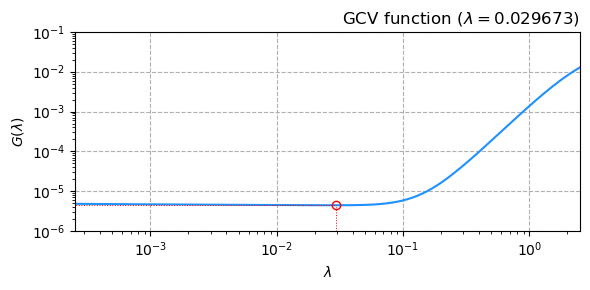

In [21]:
lam_gcv = lc.gcv_lambda(U, s, gxln, plot_gcvfun=True, plot_in_color = True, smin_ratio = 1e-4)

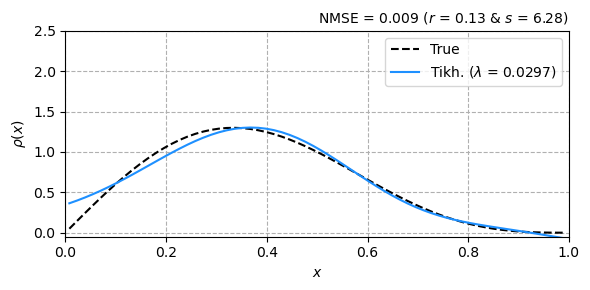

In [18]:
x_gcv = lc.tikhonov(U, s, V, gxln, lam_gcv)
nmse_gcv = lc.nmse(x_gcv, rhox)  
res_norm = np.linalg.norm(A @ x_gcv - gxln)
sol_norm = np.linalg.norm(x_gcv)

plt.figure(figsize = (6,3))
plt.plot(x, rhox, '--k', label = 'True')
plt.plot(x, x_gcv, color = 'dodgerblue', linewidth = 1.5, label = r'Tikh. ($\lambda$ = {0:.4f})'.format(lam_gcv))
plt.title(r'NMSE = {:.3f} ($r$ = {:.2f} & $s$ = {:.2f})'.format(np.round(nmse_gcv, 4), np.round(res_norm,2),
                                                                np.round(sol_norm,2)), loc = 'right', fontsize=10)
plt.ylim((0.5*np.amin(rhox),1.1*np.amax(rhox)));  
plt.grid(linestyle = '--')
plt.legend()
plt.xlim((0, 1))
plt.ylim((-0.05, 2.5)) 
plt.xlabel(r'$x$')
plt.ylabel(r'$\rho(x)$')
plt.tight_layout()

## D. *Normalized Cumulative Periodogram* (NCP)

Até aqui, os métodos descritos basearam-se na análise das normas do resíduo e/ou da solução. O método descrito nesta seção é baseado na análise espectral do vetor resíduo, que para a solução de Tikhonov é

\begin{equation}
\mathbf{r}_{\lambda} = \mathbf{Ax}_{\lambda}-\mathbf{b} = \mathbf{Ax}_{\lambda}-(\mathbf{b}_{\text{exa}}+ \mathbf{n}).
\tag{39}
\end{equation}

A pergunta feita por este método é: em que situação o vetor residual $\mathbf{r}_{\lambda} = \textbf{Ax}-\textbf{b}$ pode ser considerado dominado por ruído? 

A Transformada Discreta de Fourier (*Discrete Fourier Transform* - DFT) permite-nos responder a esta questão quando o ruído presente na medição é gaussiano (ou branco). Em suma, neste caso, o espectro médio do ruído é plano (ou constante). A técnica apresentada foi desenvolvida na área de processamento de sinais e de estatística (usando nomenclatura diferente, claro). 

Seja $\breve{\mathbf{r}}_{\lambda} = \mathcal{F}\left\{\mathbf{r}_{\lambda}\right\}$ a transformada de Fourier do vetor residual. Na prática, tal espectro será computado via DFT, calculada por meio do algoritmo da transformada rápida de Fourier (*Fast Fourier Transform* - FFT)

\begin{equation}
\breve{\mathbf{r}}_{\lambda}=\operatorname{DFT}\left\{\mathbf{r}_{\lambda}\right\}.
\tag{40}
\end{equation}

Quando temos $M$ medições, a DFT do vetor residual também será um vetor com $M$ componentes espectrais, a saber

\begin{equation}
\breve{\mathbf{r}}_{\lambda}=\left[\hat{r}_{\lambda}^{(0)}, \ \hat{r}_{\lambda}^{(1)}, \ \cdots , \ \hat{r}_{\lambda}^{(M-1)}\right]^{T} \in \mathbb{C}^{M}.
\tag{41}
\end{equation}

Os componentes do vetor $\breve{\mathbf{r}}_{\lambda}$ representam as amplitudes complexas das diversas frequências no vetor residual, com $\hat{r}_{\lambda}^{(0)}$ representando a amplitude da componente DC (constante). O espectro de potência do vetor residual é definido como o vetor real, dado pelo quadrado das magnitudes das amplitudes complexas, a saber

\begin{equation}
\mathbf{p}_{\lambda} = \breve{\mathbf{r}}_{\lambda}^H \ \breve{\mathbf{r}}_{\lambda} = \left[\left|\hat{r}_{\lambda}^{(0)}\right|^{2},\left|\hat{r}_{\lambda}^{(1)}\right|^{2}, \ldots,\left|\hat{r}_{\lambda}^{(Q)}\right|^{2}\right]^{T} \ \in \mathbb{R}^{Q}.
\tag{42}
\end{equation}

Note que $\mathbf{p}_{\lambda} \in \mathbb{R}^{Q}$. O valor de $Q$ está associado às propriedades da DFT. Para um vetor residual $\breve{\mathbf{r}}_{\lambda} \in \mathbb{R}^{M}$ (real), $Q = \left\lfloor M/2 \right\rfloor +1$ (em que $\left\lfloor M/2 \right\rfloor$ é o menor valor inteiro menor que $M/2$). Para um vetor residual $\breve{\mathbf{r}}_{\lambda} \in \mathbb{C}^{M}$ (complexo), $Q = M$.

Definimos agora o *Normalized Cumulative Periodogram* (NCP) como o vetor $\mathbf{c}\left(r_{\lambda}\right) \in \mathbb{R}^{Q}$ cujos elementos são as somas acumuladas das componentes do vetor do espectro de potência. Assim, cada componente de $\mathbf{c}\left(r_{\lambda}\right) \in \mathbb{R}^{Q}$ é dada por

\begin{equation}
c\left(\mathbf{r}_{\lambda}\right)_{i}=\frac{p_{\lambda}^{(1)}+ \cdots + p_{\lambda}^{(i)}}{p_{\lambda}^{(1)}+ \cdots + p_{\lambda}^{(Q)}}, \quad i=1, \ldots, Q.
\tag{43}
\end{equation}

A normalização na Eq. (43) garante que o maior elemento do NCP é $c\left(\mathbf{r}_{\lambda}\right)_{Q} = 1$. Note que o primeiro componente de $\mathbf{p}_{\lambda}$ (DC) não é considerado no cálculo do NCP. Por outro lado, o NCP do ruído branco (Gaussiano) é uma **reta** e tem solução analítica dada por

\begin{equation}
\textbf{c}_{\text{white}}=(1 / Q, 2 / Q, \ldots, 1)^{T}.
\tag{44}
\end{equation}

Assim, quando o NCP do vetor residual se tornar próximo de uma reta (NCP do ruído branco), isso indica que o vetor residual ficou muito semelhante ao ruído na medição. Tecnicamente computamos $d(\lambda) = \left\|\mathbf{c}\left(r_{\lambda}\right) - \textbf{c}_{\text{white}}\right\|$ (a norma da diferença entre o NCP do vetor residual e o NCP do ruído branco). Quando $d(\lambda)$ cai dentro do limite estatístico $\pm 1.35 Q−1/2$ (teste de Kolmogorov–Smirnoff) consideramos que a escolha o parâmetro de regularização levou a solução ao limite de representatividade do sinal medido (o resíduo é similar ao ruído). Assim, para escolher $\lambda$ fazemos


<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 1100px;">
\begin{equation}
\text{Escolha} \ \ \ \lambda  \ \ \ \text{para minimizar} \ \ \ d(\lambda)=\left\|\textbf{c}\left(\mathbf{r}_{\lambda}\right)-\textbf{c}_{\text {white }}\right\|_{2}
\tag{45}
\end{equation}
</div>

E para a TSVD

<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 1100px;">
\begin{equation}
\text{Escolha} \ \ \ k  \ \ \ \text{para minimizar} \ \ \ d(k)=\left\|\textbf{c}\left(\mathbf{r}_{k}\right)-\textbf{c}_{\text {white }}\right\|_{2}
\tag{46}
\end{equation}
</div>

#### Vejamos algum código (as partes mais importantes)

Note as partes gerais do algoritmo dado anteriormente.

```python
def ncp(U, s, b, smin_ratio = 16 * np.finfo(float).eps,
        plotcp = False, plot_in_color = True):
    """ Normalized Cumulative Periodgram regularization criterion
    
    Finds the optmimal regularization parameter for Tikhonov regularization 
    according to the NCP criterion (see Sec. 5.5 of Discrete Inverse Problems)
    
    Parameters
    ------------
    U : numpyndArray
        Left singular vectors matrix
    s : numpy1dArray
        Singular values
    b : numpy1dArray
        Measurement vector
    smin_ratio : float
        ratio to first singular value. Odds are that the minimum regularization 
        parameter will be s[0]*smin_ratio
    plotcp : bool
        choose to plot the regularization function or not.
    plot_in_color : bool
        choose to plot the regularization function in color or black and white.
    """
    # Sizes and shapes
    m = U.shape[0]
    p = len(s)
    npoints, nNCPs = 200, 20
    # beta - b projection on U
    beta = np.conj(U.T) @ b
    # Initial search grid
    reg_param = get_regpar(s_valid = s[:p], npoints = npoints, smin_ratio = smin_ratio)
    # Inits
    dists = np.zeros(npoints) # Norm of cp-c_white
    q = get_q_ncp(beta, m)
    cp = np.zeros((q-1, npoints)) # cp
    # Fill cp and norm of cp-c_white
    for i in range(npoints):
        dists[i], cp[:, i], _ = ncpfun(reg_param[i], s, beta[:p], U[:, :p])
    # Initial minimization    
    x1, x2, tolerance = get_bounds(vec_to_minimize = dists, 
                                   reg_par_vec = reg_param)
    # Final miminization
    reg_min_result = optimize.fminbound(clean_ncpfun, x1, x2, args = (s[:p], beta[:p], U[:, :p]), 
                                        xtol=tolerance, full_output=False, disp=False)
    # Final evalutaion of NCP funtion
    dist, cp_opt, cp_white = ncpfun(reg_min_result, s[:p],  beta[:p], U[:, :p])
    return reg_min_result
```

```python
def ncpfun(lambda_val, s, beta, U, dsvd=False):
    """ NCP function
    
    Parammeters
    -------------
    lambda_val : float
        Value of the regularization parameter
    s : numpy1dArray
        Singular values
    dsvd : bool
        Computational mode of filter factors
    """
    # Filter factors
    f = complement_filter_factors(lambda_val, s, check_s_sq = dsvd)
    # Resudual norm, m and q
    r = U @ (f * beta)
    m = len(r)   
    q = get_q_ncp(beta, m)
    # FFT of residual norm and its NCP
    D = np.abs(np.fft.fft(r)) ** 2
    D = D[1:q]
    cp = np.cumsum(D) / np.sum(D) # NCP of r
    # NCP of white noise
    c_white = np.arange(1, q) / (q-1)
    # distance (norm of cp-v)
    dist = np.linalg.norm(cp - c_white)
    return dist, cp, c_white
```

### Algumas palavras de cautela:

Infelizmente, nem sempre o ruído ou as discrepâncias do modelo presentes no vetor $\mathbf{n}$ terão características de ruído branco. Nestes casos, o método falhará.

### Vejamos o critério NCP no problema investigado

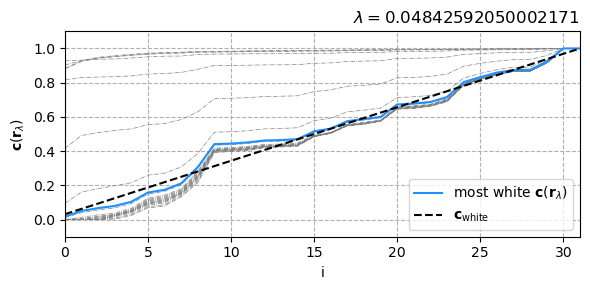

In [22]:
lam_ncp= lc.ncp(U, s, gxln, plotcp=True, plot_in_color = True, smin_ratio = 0.00001)

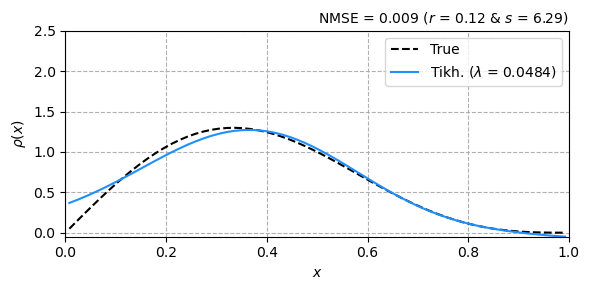

In [23]:
x_ncp = lc.tikhonov(U, s, V, gxln, lam_ncp)
nmse_ncp = lc.nmse(x_ncp, rhox)  
res_norm = np.linalg.norm(A @ x_lc - gxln)
sol_norm = np.linalg.norm(x_lc)

plt.figure(figsize = (6,3))
plt.plot(x, rhox, '--k', label = 'True')
plt.plot(x, x_ncp, color = 'dodgerblue', linewidth = 1.5, label = r'Tikh. ($\lambda$ = {0:.4f})'.format(lam_ncp))
plt.title(r'NMSE = {:.3f} ($r$ = {:.2f} & $s$ = {:.2f})'.format(np.round(nmse_ncp, 4), np.round(res_norm,2),
                                                                np.round(sol_norm,2)), loc = 'right', fontsize=10)
plt.ylim((0.5*np.amin(rhox),1.1*np.amax(rhox)));  
plt.grid(linestyle = '--')
plt.legend()
plt.xlim((0, 1))
plt.ylim((-0.05, 2.5)) 
plt.xlabel(r'$x$')
plt.ylabel(r'$\rho(x)$')
plt.tight_layout()

# 7. Testando outros solvers

O solver que usamos até aqui essencialmente reproduz a Eq. (11). No entanto, é possível implementar a solução de outras maneiras, e haverá diferenças numéricas. Vamos usar o parâmetro de regularização obtido pela curva L e testar os solvers: CVX e Ridge (Sklearn)

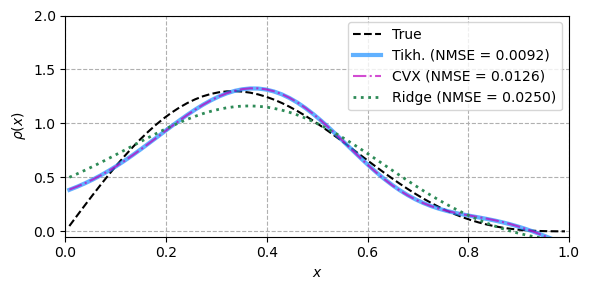

In [24]:
# CVX
x_lc_cvx = lc.cvx_tikhonov(A, gxln, lam_lc, l_norm = 2)
nmse_cvx = lc.nmse(x_lc_cvx, rhox)

# Ridge
regressor = sklearn.linear_model.Ridge(alpha=lam_lc, fit_intercept = False, solver = 'svd')
x_lc_ridge = regressor.fit(A, gxln).coef_
nmse_ridge = lc.nmse(x_lc_ridge, rhox)

plt.figure(figsize = (6,3))
plt.plot(x, rhox, '--k', label = 'True')
plt.plot(x, x_lc, linewidth = 3.0, color = 'dodgerblue', alpha = 0.7, label = r'Tikh. (NMSE = {0:.4f})'.format(nmse_gcv))
plt.plot(x, np.real(x_lc_cvx), linewidth = 1.5, color = 'm', linestyle = '-.', alpha = 0.7, label = r'CVX (NMSE = {0:.4f})'.format(nmse_cvx))
plt.plot(x, x_lc_ridge, linewidth = 2.0, color = 'seagreen', linestyle = ':', alpha = 1.0, label = r'Ridge (NMSE = {0:.4f})'.format(nmse_ridge))

plt.ylim((0.5*np.amin(rhox),1.1*np.amax(rhox)));  
plt.grid(linestyle = '--')
plt.legend()
plt.xlim((0, 1))
plt.ylim((-0.05, 2)) 
plt.xlabel(r'$x$')
plt.ylabel(r'$\rho(x)$')
plt.tight_layout()

# 8. Reconstrução

se você computou uma boa aproximação da causa do problema, talvez você possa inferir algo sobre o fenômeno em questão em locais onde você não mediu. Desejamos **reconstruir** uma quantidade desejada em pontos não observados da variável independente.

Por exemplo, no problema da gravidade, medimos a aceleração da gravidade, $g(x')$, a uma distância $d$ [m] e inferimos o termo-fonte, $\rho(x)$. Seria útil, no entanto, reconstruir a aceleração da gravidade para valores $d$ menores ou maiores que o medido. Vamos reconstruir a aceleração da gravidade onde não a observamos diretamente. 

Note que:

- $d = 0$ m representa uma origem hipotética para o campo de densidades. É o nosso termo fonte e, usualmente, não conseguimos reconstruir nada para $d \leq 0$ (nossa área de reconstrução não deve **conter fontes**);
- Mas podemos reconstruir $g(x')$ para outros valores de $d$ (mais perto ou mais longe do plano de medição).

A reconstrução é um **problema direto** (*forward problem*). Note que já computamos $\textbf{x}$ pelo problema inverso regularizado. Precisamos então computar

\begin{equation}
\textbf{b}_{\text{r}} = \textbf{A}_{\text{r}} \hat{\textbf{x}}
\end{equation}
em que $\textbf{A}_{\text{r}}$ é a matriz de reconstrução avaliada nas posições de reconstrução desejadas.

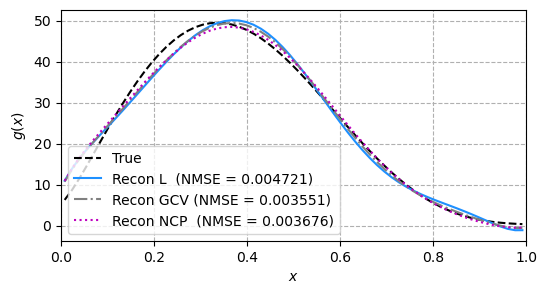

In [25]:
# distancia desejada
dr = 0.05

# Matriz de reconstrução
Ar, xr = tp.gravity_model(n = order,a = a, b = b, d = dr)

# Ground Truth
gxt = Ar @ rhox

# reconstruido L-curve
gx_lc = Ar @ x_lc
nmse_lc = lc.nmse(gx_lc, gxt)

# reconstruido GCV
gx_gcv = Ar @ x_gcv
nmse_gcv = lc.nmse(gx_gcv, gxt)

# reconstruido NCP
gx_ncp = Ar @ x_ncp
nmse_ncp = lc.nmse(gx_ncp, gxt)

############ Figure ###########################
plt.figure(figsize = (6,3))
plt.plot(x, gxt, '--k', label = 'True')
plt.plot(x, gx_lc, '-', color = 'dodgerblue', label = 'Recon L  (NMSE = {0:.6f})'.format(nmse_lc))
plt.plot(x, gx_gcv, '-.', color = 'grey', label = 'Recon GCV (NMSE = {0:.6f})'.format(nmse_gcv))
plt.plot(x, gx_ncp, ':', color = 'm', label = 'Recon NCP  (NMSE = {0:.6f})'.format(nmse_ncp))
plt.legend()
plt.grid(linestyle = '--')
plt.xlim((0, 1))
plt.xlabel(r'$x$')
plt.ylabel(r'$g(x)$');

# 9. Testando os métodos estatisticamente

Uma característica importante do ruído de medição é que é aleatório. Ou seja, a cada conjunto de medidas que tomamos, teremos uma contaminação diferente no vetor $\mathbf{b}$. Se os experimentos forem bem feitos, esperamos que o ruído seja apenas ligeiramente diferente entre medições diferentes. Imaginemos então que tenhamos um ruído gaussiano, dado por

\begin{equation}
\mathbf{n} = \mathcal{N}(\mu_x, \sigma_x),
\end{equation}
em que $\mu_x = 0$ é o valor médio do vetor de ruído e $\sigma_x$ é sua variância (ligada à relação sinal-ruído - SNR).

Podemos simular $n_{\text{meas}}$ medições do problema de gravidade e avaliar a distribuição estatística do parâmetro de regularização e do erro normalizado (NMSE) obtido da solução sensata [$x_{\lambda}$] vs. a solução exata [$x_{\text{exa}}$]. Na prática, desejamos que o NMSE seja o menor possível e que o parâmetro de regularização tenha uma distribuição estatística com média próxima à do parâmetro de regularização ótimo ($\lambda_{\text{opt}}$), com a menor variância possível. Podemos definir

\begin{equation}
\lambda_{\text{opt}} = \underset{\lambda}{\operatorname{\text{argmin}}}(x_{\text{exa}}-x_{\lambda})
\end{equation}

Computemos então $n_{\text{meas}}$ medições com ruído aleatório e suas respectivas soluções sensatas por DP, L-curve, GCV e NCP. Para mostrar a distribuição do parâmetro de regularização, adotamos a razão

\begin{equation}
\Lambda(\text{method}) = \frac{\lambda_{\text{method}}}{\lambda_{\text{opt}}},
\end{equation}
que idealmente deve se distribuir em torno de $1.0$ com uma pequena variância. Avaliemos os histogramas de $\Lambda$ e do NMSE para diferentes SNR.

In [29]:
np.random.seed(0)
n_meas = 250
snr = -30
smin_ratio = 1e-12
# lambda
lam_dp_vec = np.zeros(n_meas)
lam_lc_vec = np.zeros(n_meas)
lam_gcv_vec = np.zeros(n_meas)
lam_ncp_vec = np.zeros(n_meas)
lam_ideal_vec = np.zeros(n_meas)
lambda_vals = np.linspace(0.001, 0.1, 1000)
# NMSE
nmse_dp_vec = np.zeros(n_meas)
nmse_lc_vec = np.zeros(n_meas)
nmse_gcv_vec = np.zeros(n_meas)
nmse_ncp_vec = np.zeros(n_meas)
# Main loop
bar = tqdm(total=n_meas, desc='Calculating...', ascii=False)
for m in range(n_meas):
    rhox = tp.density_sin(x, 0.5) + 0.5* tp.density_sin(x, 1.0)  
    #rhox = tp.density_rechann(x, hann_x = 0.5)
    # noiseless meas
    gxl = A @ rhox
    # Generate measurement instance and add
    noise = np.random.normal(loc = 0.0, scale = 1, size = len(gxl))
    noise /= np.linalg.norm(noise)
    noise *= (10**(snr/10))*np.linalg.norm(gxl)
    gxln = gxl + noise
    # DP
    x_dp, lam_dp = lc.discrep(U, s, V, gxln, 1*np.linalg.norm(noise))
    lam_dp_vec[m] = lam_dp[0]
    x_lam = lc.tikhonov(U, s, V, gxln, lam_dp)
    nmse_dp_vec[m] = lc.nmse(x_lam, rhox)
    # l-curve
    lam_lc_vec[m] = lc.l_curve_new(U, s, gxln, smin_ratio = smin_ratio, plotit = False)
    x_lam = lc.tikhonov(U, s, V, gxln, lam_lc_vec[m])
    nmse_lc_vec[m] = lc.nmse(x_lam, rhox)
    # GCV
    lam_gcv_vec[m] = lc.gcv_lambda(U, s, gxln, plot_gcvfun = False, smin_ratio = smin_ratio)
    x_lam = lc.tikhonov(U, s, V, gxln,  lam_gcv_vec[m])
    nmse_gcv_vec[m] = lc.nmse(x_lam, rhox)
    # NCP
    lam_ncp_vec[m] = lc.ncp(U, s, gxln, plotcp=False, smin_ratio = smin_ratio)
    x_lam = lc.tikhonov(U, s, V, gxln,  lam_ncp_vec[m])
    nmse_ncp_vec[m] = lc.nmse(x_lam, rhox)
    # Find ideal lambda
    snorm_vec = np.zeros(len(lambda_vals))
    for jl, lam in enumerate(lambda_vals):
        x_lam = lc.tikhonov(U, s, V, gxln, lam)
        snorm_vec[jl] = np.linalg.norm(x_lam - rhox)
    id_lam = np.argmin(snorm_vec)
    lam_ideal_vec[m] = lambda_vals[id_lam]
    bar.update(1)
bar.close()
# Normalization    
R_DP = lam_dp_vec / lam_ideal_vec#np.mean(lam_ideal_vec)
R_LC = lam_lc_vec / lam_ideal_vec#np.mean(lam_ideal_vec)
R_GCV = lam_gcv_vec / lam_ideal_vec#np.mean(lam_ideal_vec)
R_NCP = lam_ncp_vec / lam_ideal_vec#np.mean(lam_ideal_vec)

Calculating...: 100%|██████████| 250/250 [00:08<00:00, 29.68it/s]


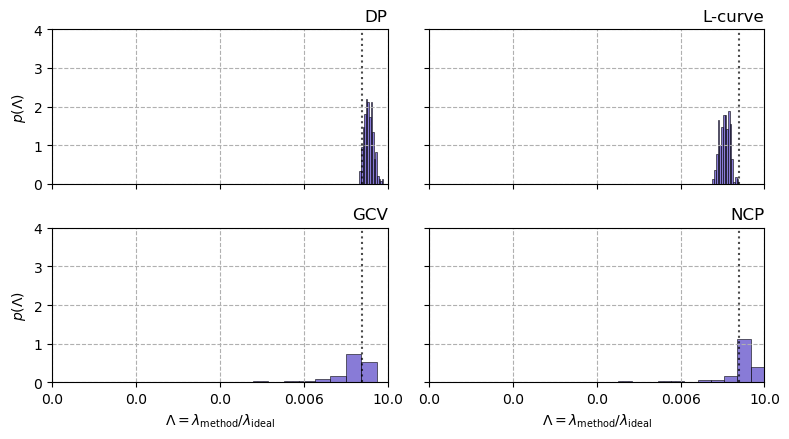

In [30]:
titles = ['DP', 'L-curve', 'GCV', 'NCP']
data = [lam_dp_vec, lam_lc_vec, lam_gcv_vec, lam_ncp_vec]
data = [R_DP, R_LC, R_GCV, R_NCP]
ticks = np.linspace(np.log10(smin_ratio),1,5) 
fig, axs = plt.subplots(2, 2, figsize = (8,4.5), sharex=True, sharey=True)
j=0
for r in range(2):
    for c in range(2):
        axs[r,c].axvline(0, linestyle = ':', color = 'k', alpha = 0.7)
        axs[r,c].hist(np.log10(data[j]), bins = 15, color = 'slateblue', edgecolor='k', linewidth= 0.5, alpha = 0.8, density = True);
        axs[r,c].set_xticks(ticks)
        axs[r,c].set_xticklabels(np.round(10**ticks,3))
        axs[r,c].grid(linestyle = '--')
        axs[r,c].set_title(titles[j], loc = 'right')
        axs[r,c].set_xlim((ticks[0], ticks[-1]))
        axs[r,c].set_ylim((0, 4))
        axs[1,c].set_xlabel(r"$\Lambda=\lambda_{{\text{method}}}/\lambda_{{\text{ideal}}}$")
        j += 1
    axs[r,0].set_ylabel(r"$p(\Lambda)$")
plt.tight_layout()

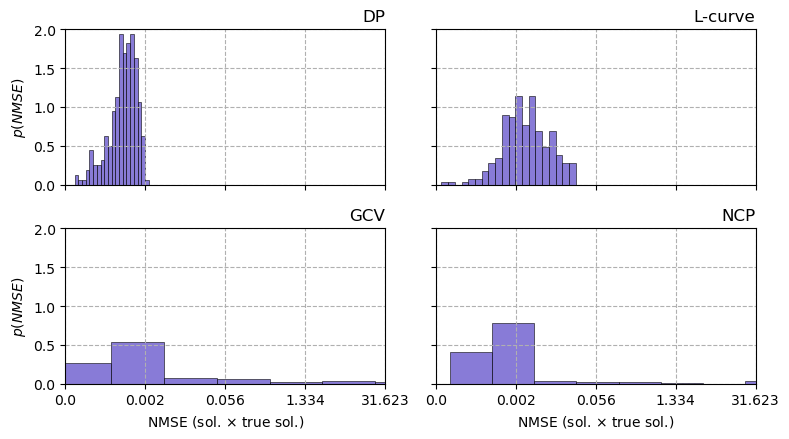

In [31]:
data = [nmse_dp_vec, nmse_lc_vec, nmse_gcv_vec, nmse_ncp_vec]
ticks = np.linspace(-4, 1.5, 5) 
fig, axs = plt.subplots(2, 2, figsize = (8,4.5), sharex=True, sharey=True)
j=0
for r in range(2):
    for c in range(2):
        axs[r,c].hist(np.log10(data[j]), bins = 20, color = 'slateblue', edgecolor='k', linewidth= 0.5, alpha = 0.8, density = True);
        axs[r,c].set_xticks(ticks)
        axs[r,c].set_xticklabels(np.round(10**ticks,3))
        axs[r,c].grid(linestyle = '--')
        axs[r,c].set_title(titles[j], loc = 'right')
        axs[r,c].set_xlim((-4, 1.5))
        axs[r,c].set_ylim((0, 2))
        axs[1,c].set_xlabel(r"NMSE (sol. $\times$ true sol.)")
        j += 1
    axs[r,0].set_ylabel(r"$p(NMSE)$")
plt.tight_layout()

# Exercícios

### 1. Parâmetro de regularização (DP, L-curve, GCV e NCP) para diferentes realizações de ruído.

Para o problema da gravidade analisado aqui, refaça as análises do parâmetro de regularização de Tikhonov para diferentes realizações de ruído - mude np.random.seed(x) em cada nova realização. Use os métodos L-curve, GCV e NCP. Tente variar o parâmetro "smin_ratio" entre 1e-16 e 0.01. Será que a escolha de $\lambda$ é sempre consistente? O que pode acontecer se "smin_ratio" for muito pequeno? Por que?

Tente fazer a análise também com os termos fonte "density_pieciwise" e "density_rechann".

### 2. Testes estatísticos no problema do calor na barra.

Refaça os testes estatísticos da Seção 9 para o problema do calor na barra. Considere o uso de diferentes termos-fonte. As conclusões sobre qual é o melhor método de escolha automática mudam neste caso?

### 3. Análise de sensibilidade da solução.
O objetivo deste exercício é investigar o grau de sensibilidade das soluções regularizadas a perturbações, uma vez que um parâmetro de regularização tenha sido calculado por meio do GCV ou do critério da curva L. O exercício também ilustra que o parâmetro de regularização depende tanto do ruído que é impossível selecioná-lo a priori.

Gere seu problema de teste preferido, adicione ruído gaussiano com uma determinada SNR e calcule os parâmetros de regularização $\lambda_{\text{GCV}}$ e $\lambda_{\text{L}}$ para a regularização de Tikhonov. Certifique-se de que esses parâmetros sejam razoáveis; caso contrário, gere o ruído novamente.

Agora crie uma série de problemas com diferentes realizações do ruído e (com a mesma SNR) adicionadas ao $\mathbf{b}_{\text{exa}}$. Para cada realização do ruído, calcule as soluções de Tikhonov usando os mesmos dois parâmetros de regularização $\lambda_{\text{GCV}}$ e $\lambda_{\text{L}}$ calculados anteriormente e calcule o NMSE. Quão sensíveis são as soluções às variações na realização do ruído?


# Export para matlab (para testes)

In [11]:
import scipy.io
file_path = 'gravity_64_26_seed3.mat'
scipy.io.savemat(file_path, {'A': A,
                            'x': x,
                            'rhox': rhox,
                            'n': n,
                            'gxl': gxl,
                            'gxln' : gxln,
                            'U': U,
                            's': s,
                            'V': V})